# Part (a): Deep Q-Network on CartPole-v1

Double DQN (online network + Polyak-averaged target network + replay buffer) that has to balance the pole for 500 steps with the prescribed discount factor $\gamma = 0.95$.

**Structure of this notebook**
1. Setup: hyperparameters, discount horizon, $\epsilon$ schedule
2. DQN building blocks: network, replay buffer, training loop, evaluation, plotting
3. Hyperparameter ladder: baseline, then one change at a time (cumulative), each with the required plots (i)–(iii)
4. Robustness across seeds (baseline vs. best configuration)
5. Non-standard plot: phase portraits of greedy trajectories
6. Edge cases
7. Validation tests (each prints `[PASS]` / `[FAIL]`)

**How to run.** Run all cells from top to bottom. Every training run is cached in `checkpoints/a/<variant>/seed<k>/` (`log.npz`, `snapshots.pt`, `config.json`). With `RETRAIN = False`, a cached run is loaded instead of retrained, as long as its saved config matches the current one (a changed config is retrained automatically). All figures are written to `report/figures/a_*.png`.

In [1]:
import copy
import json
import math
import random
from dataclasses import asdict, dataclass, field, replace
from functools import cached_property
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection
from torch import nn, optim
from tqdm.auto import tqdm

ROOT = Path.cwd()  # the notebook's folder (hw-2/)
FIGURES = ROOT / "report" / "figures"
CHECKPOINTS = ROOT / "checkpoints" / "a"
FIGURES.mkdir(parents=True, exist_ok=True)
CHECKPOINTS.mkdir(parents=True, exist_ok=True)

RETRAIN = False  # True: retrain every run even if a cached run exists

# A 2-layer MLP with batch size 32 is faster on one CPU thread than on the GPU
torch.set_num_threads(1)

# Environment constants
GAMMA = 0.95  # prescribed by the assignment
MAX_STEPS = 500  # CartPole-v1 time limit
SOLVED = 475  # CartPole-v1 counts as solved at a 100-episode mean of 475
N_ACTIONS, STATE_DIM = 2, 4
X_LIMIT = 2.4  # cart leaves the track
THETA_LIMIT = 12 * 2 * math.pi / 360  # pole falls (0.2095 rad)
START = {"low": -0.15, "high": 0.15}  # start states, same as hw-1 (default is +-0.05)
WIDE_START = {"low": -0.2, "high": 0.2}

# Experiment constants
N_EPISODES = 1_000  # every run trains for the same number of episodes
N_EVAL = 500  # greedy roll-outs after training (assignment iii)
WINDOW = 100  # moving average over the last 100 episodes (assignment ii)
SEEDS = (0, 1, 2)
SNAPSHOT_EPISODES = (
    0,
    100,
    200,
    300,
    500,
    1_000,
)  # weights kept for the phase portraits
PHASE_SEED = 7  # start state used for all phase portraits
VAL_SEED, N_VAL = (
    100_000,
    20,
)  # validation start states for checkpoint selection (test uses seeds 0..499)

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "legend.frameon": False,
    }
)
COLORS = plt.cm.tab10.colors


def save_figure(fig: plt.Figure, name: str) -> None:
    fig.savefig(FIGURES / f"a_{name}.png", dpi=150, bbox_inches="tight")


def q_bound(gamma: float) -> float:
    """Largest possible Q-value with reward +1 per step: sum of gamma^k = 1 / (1 - gamma)."""
    return 1 / (1 - gamma) if gamma < 1 else float(MAX_STEPS)

## 1. Setup

All hyperparameters of a run live in one `Config`. The **hyperparameter ladder** starts from a deliberately simple baseline and changes **exactly one** parameter per step, keeping all earlier changes (cumulative). Every run trains for 1,000 episodes, so the curves are directly comparable. A run with $\gamma = 0.99$ (on top of v4) is only a side experiment about the horizon: the reported final model uses $\gamma = 0.95$, as the assignment requires.

**v5: reward shaping + best checkpoint.** v0–v4 showed that with $\gamma = 0.95$ the cart leaving the track is the dominant failure (Test 8, phase portraits). v5 therefore multiplies the reward by $1 - (x'/2.4)^2$, with $x'$ the cart position after the step: 1 in the centre, 0 at the edge. The shaped reward stays $\geq 0$, so surviving longer is never worse than failing, and Q stays bounded by 20. It is only used for learning; **all reported rewards are the environment rewards**. In addition, v5 evaluates the greedy policy every 50 episodes on 20 *validation* start states and keeps the best weights ("best checkpoint"). This does not change training: the evaluation uses its own environment and random generator.

In [2]:
@dataclass(frozen=True)
class Config:
    name: str  # folder name of the run
    label: str  # label in plots and tables
    gamma: float = GAMMA
    episodes: int = N_EPISODES
    hidden: tuple[int, ...] = (32,)
    buffer_size: int = 2_000
    batch_size: int = 32
    learning_starts: int = 1_000  # transitions in the buffer before the first update
    lr: float = 5e-4
    tau: float = 0.02  # Polyak factor of the target network (1.0 = no target network)
    loss: str = "mse"  # "mse" or "huber"
    grad_clip: float | None = None
    double: bool = True  # Double DQN: online net selects, target net evaluates
    eps_start: float = 1.0
    eps_end: float = 0.01
    eps_decay: float = 5.0  # eps(e) = end + (start - end) * exp(-decay * e / episodes)
    reward_sign: float = 1.0  # -1.0 only for the negated-reward control experiment
    shaping: str | None = None  # "center": reward * (1 - (x' / 2.4)^2)
    eval_every: int | None = (
        None  # greedy validation every n episodes, keeps the best weights
    )


def epsilon(config: Config, episode: int) -> float:
    return config.eps_end + (config.eps_start - config.eps_end) * math.exp(
        -config.eps_decay * episode / config.episodes
    )


def shaped_reward(config: Config, reward: float, next_state) -> float:
    """Reward used for learning (the logged episode reward is always the environment reward)."""
    if config.shaping == "center":
        reward = reward * max(0.0, 1.0 - (next_state[0] / X_LIMIT) ** 2)
    return config.reward_sign * reward


BASELINE = Config("v0_baseline", "Baseline")
LADDER = [BASELINE]
LADDER.append(
    replace(LADDER[-1], name="v1_buffer", label="+ buffer 50k", buffer_size=50_000)
)
LADDER.append(replace(LADDER[-1], name="v2_tau", label="+ τ = 0.005", tau=0.005))
LADDER.append(replace(LADDER[-1], name="v3_net", label="+ 128 hidden", hidden=(128,)))
LADDER.append(
    replace(
        LADDER[-1],
        name="v4_huber",
        label="+ Huber & clip",
        loss="huber",
        grad_clip=10.0,
    )
)
SIDE_GAMMA = replace(
    LADDER[-1], name="side_gamma099", label="γ = 0.99 (side)", gamma=0.99
)
LADDER.append(
    replace(
        LADDER[-1],
        name="v5_shaping",
        label="+ reward shaping",
        shaping="center",
        eval_every=50,
    )
)

for c in LADDER + [SIDE_GAMMA]:
    print(
        f"{c.name:<14} γ={c.gamma}  hidden={c.hidden}  buffer={c.buffer_size:>6}  "
        f"τ={c.tau}  loss={c.loss}  clip={c.grad_clip}  shaping={c.shaping}  eval_every={c.eval_every}"
    )

v0_baseline    γ=0.95  hidden=(32,)  buffer=  2000  τ=0.02  loss=mse  clip=None  shaping=None  eval_every=None
v1_buffer      γ=0.95  hidden=(32,)  buffer= 50000  τ=0.02  loss=mse  clip=None  shaping=None  eval_every=None
v2_tau         γ=0.95  hidden=(32,)  buffer= 50000  τ=0.005  loss=mse  clip=None  shaping=None  eval_every=None
v3_net         γ=0.95  hidden=(128,)  buffer= 50000  τ=0.005  loss=mse  clip=None  shaping=None  eval_every=None
v4_huber       γ=0.95  hidden=(128,)  buffer= 50000  τ=0.005  loss=huber  clip=10.0  shaping=None  eval_every=None
v5_shaping     γ=0.95  hidden=(128,)  buffer= 50000  τ=0.005  loss=huber  clip=10.0  shaping=center  eval_every=50
side_gamma099  γ=0.99  hidden=(128,)  buffer= 50000  τ=0.005  loss=huber  clip=10.0  shaping=None  eval_every=None


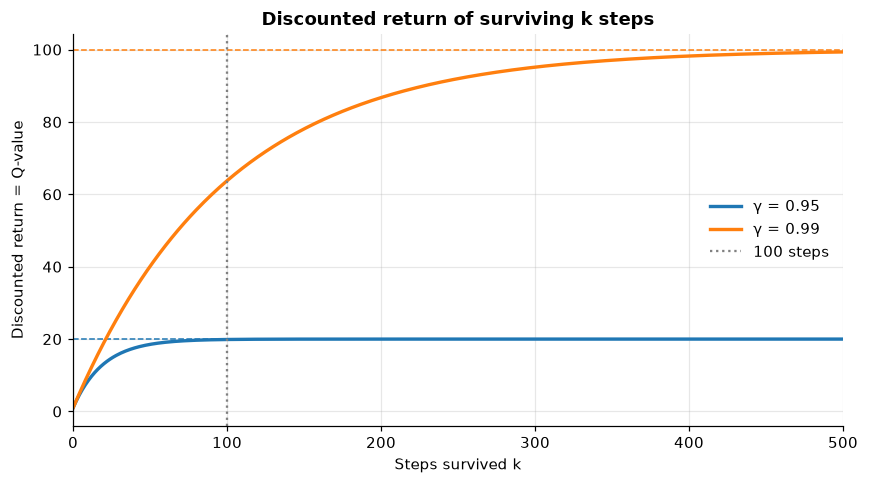

γ = 0.95: γ^100 = 0.0059, bound 1/(1-γ) = 20


In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
k = np.arange(MAX_STEPS)
for gamma, color in [(0.95, COLORS[0]), (0.99, COLORS[1])]:
    ax.plot(
        k,
        (1 - gamma ** (k + 1)) / (1 - gamma),
        color=color,
        lw=2.2,
        label=f"γ = {gamma}",
    )
    ax.axhline(q_bound(gamma), color=color, ls="--", lw=1)
ax.axvline(100, color="gray", ls=":", lw=1.5, label="100 steps")
ax.set(
    title="Discounted return of surviving k steps",
    xlabel="Steps survived k",
    ylabel="Discounted return = Q-value",
    xlim=(0, MAX_STEPS),
)
ax.legend(loc="center right")
fig.tight_layout()
save_figure(fig, "discount_horizon")
plt.show()
print(f"γ = 0.95: γ^100 = {0.95**100:.4f}, bound 1/(1-γ) = {q_bound(0.95):.0f}")

With $\gamma = 0.95$ the Q-value of surviving forever is bounded by $1/(1-\gamma) = 20$, and after ~100 steps it is already at 99.4 % of that bound ($\gamma^{100} \approx 0.006$). Rewards further in the future barely influence the DQN's targets, so the agent effectively only "sees" the next ~60–100 steps. A slow drift of the cart towards the edge of the track, which only causes a failure much later, is therefore hardly punished (see the end-reason test in Section 7).

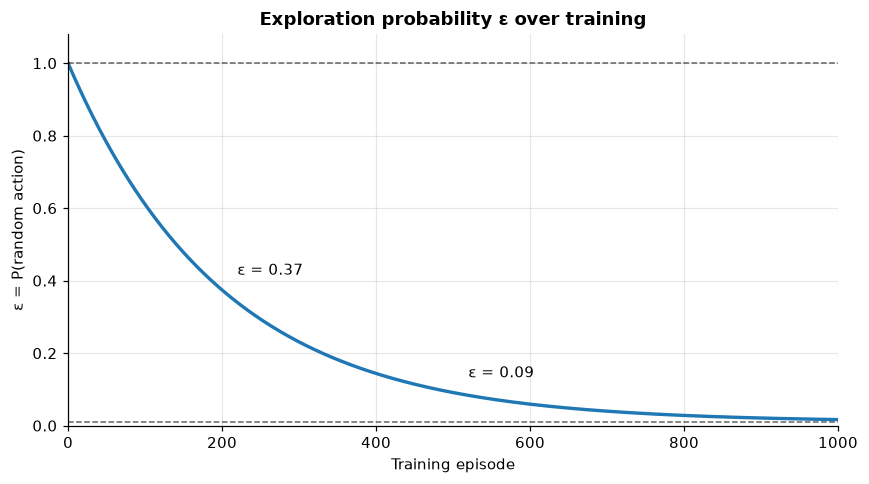

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
episodes = np.arange(BASELINE.episodes)
ax.plot(episodes, [epsilon(BASELINE, e) for e in episodes], color=COLORS[0], lw=2.2)
for value in (BASELINE.eps_start, BASELINE.eps_end):
    ax.axhline(value, color="black", ls="--", lw=1, alpha=0.6)
for e in (200, 500):
    ax.annotate(
        f"ε = {epsilon(BASELINE, e):.2f}",
        (e, epsilon(BASELINE, e)),
        xytext=(10, 10),
        textcoords="offset points",
    )
ax.set(
    title="Exploration probability ε over training",
    xlabel="Training episode",
    ylabel="ε = P(random action)",
    xlim=(0, BASELINE.episodes),
    ylim=(0, 1.08),
)
fig.tight_layout()
save_figure(fig, "epsilon_schedule")
plt.show()

## 2. DQN Building Blocks

In [5]:
class DQN(nn.Module):
    """MLP state -> Q-value of each action."""

    def __init__(self, hidden: tuple[int, ...] = (32,)) -> None:
        super().__init__()
        layers, width = [], STATE_DIM
        for h in hidden:
            layers += [nn.Linear(width, h), nn.ReLU()]
            width = h
        layers.append(nn.Linear(width, N_ACTIONS))
        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class ReplayBuffer:
    """Ring buffer of transitions (s, a, r, s', terminated); the oldest is overwritten first."""

    def __init__(self, capacity: int) -> None:
        self.capacity, self.idx, self.size = capacity, 0, 0
        self.states = np.zeros((capacity, STATE_DIM), np.float32)
        self.actions = np.zeros(capacity, np.int64)
        self.rewards = np.zeros(capacity, np.float32)
        self.next_states = np.zeros((capacity, STATE_DIM), np.float32)
        self.dones = np.zeros(capacity, np.float32)

    def __len__(self) -> int:
        return self.size

    def push(self, state, action, reward, next_state, terminated) -> None:
        i = self.idx
        self.states[i], self.actions[i], self.rewards[i] = state, action, reward
        self.next_states[i], self.dones[i] = next_state, float(terminated)
        self.idx = (self.idx + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, n: int, rng: np.random.Generator) -> tuple[torch.Tensor, ...]:
        idx = rng.integers(0, self.size, size=n)  # uniform, with replacement
        return tuple(
            torch.from_numpy(a[idx])
            for a in (
                self.states,
                self.actions,
                self.rewards,
                self.next_states,
                self.dones,
            )
        )


@torch.no_grad()
def q_values(net: nn.Module, states) -> np.ndarray:
    return net(torch.as_tensor(np.asarray(states), dtype=torch.float32)).numpy()


@torch.no_grad()
def td_targets(
    online, target, rewards, next_states, dones, gamma, double
) -> torch.Tensor:
    """y = r + gamma * Q_target(s', a*) * (1 - terminated), no gradient flows into the targets."""
    q_next_target = target(next_states)
    selector = online(next_states) if double else q_next_target
    best_next = selector.argmax(dim=1, keepdim=True)
    q_next = q_next_target.gather(1, best_next).squeeze(1)
    return rewards + gamma * q_next * (1 - dones)


def learn_step(online, target, optimizer, buffer, config, rng) -> float:
    states, actions, rewards, next_states, dones = buffer.sample(config.batch_size, rng)
    y = td_targets(
        online, target, rewards, next_states, dones, config.gamma, config.double
    )
    q = online(states).gather(1, actions.unsqueeze(1)).squeeze(1)
    loss = F.mse_loss(q, y) if config.loss == "mse" else F.smooth_l1_loss(q, y)
    optimizer.zero_grad()
    loss.backward()
    if config.grad_clip is not None:
        nn.utils.clip_grad_norm_(online.parameters(), config.grad_clip)
    optimizer.step()
    return loss.item()


@torch.no_grad()
def soft_update(target: nn.Module, online: nn.Module, tau: float) -> None:
    """Polyak averaging: target <- tau * online + (1 - tau) * target."""
    for t, o in zip(target.parameters(), online.parameters()):
        t.lerp_(o, tau)

**Training loop.** Per step: the online network computes $Q(s,\cdot)$ (logged for the max-Q plot), the action is $\epsilon$-greedy, the transition is stored with `terminated` (not `truncated`) as the done flag together with the (possibly shaped) learning reward, and once the buffer holds `learning_starts` transitions, one gradient step and one Polyak update follow. Per episode we log the environment reward, the maximum and mean of $\max_a Q(s,a)$ over the visited states, the mean loss, $\epsilon$, why the episode ended and the largest $|x|$ of the cart. The weights at `SNAPSHOT_EPISODES` are kept for the phase portraits. With `eval_every`, the greedy policy is also evaluated on `N_VAL` validation start states every `eval_every` episodes, and the best weights are kept as `snapshots["best"]`.

In [6]:
END_NAMES = ("pole", "cart", "time limit")


def end_reason(state, terminated: bool) -> str:
    if not terminated:
        return "time limit"
    return "cart" if abs(state[0]) > X_LIMIT else "pole"


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def clone_state(net: nn.Module) -> dict:
    return {k: v.detach().clone() for k, v in net.state_dict().items()}


def load_net(config: Config, state: dict) -> DQN:
    net = DQN(config.hidden)
    net.load_state_dict(state)
    return net.eval()


def train(config: Config, seed: int = 0, progress: bool = True) -> tuple[dict, dict]:
    set_seed(seed)
    rng = np.random.default_rng(seed)
    env = gym.make("CartPole-v1")
    online = DQN(config.hidden)
    target = copy.deepcopy(online)
    optimizer = optim.Adam(online.parameters(), lr=config.lr)
    buffer = ReplayBuffer(config.buffer_size)

    keys = ("reward", "max_q", "mean_q", "loss", "epsilon", "end", "max_abs_x")
    if config.eval_every:
        keys += ("eval_episode", "eval_mean")
    log = {k: [] for k in keys}
    snapshots = {0: clone_state(online)}
    best_score, best_episode = -1.0, 0
    snapshot_episodes = {e for e in SNAPSHOT_EPISODES if e <= config.episodes} | {
        config.episodes
    }

    pbar = tqdm(
        range(1, config.episodes + 1),
        desc=f"{config.label} (seed {seed})",
        disable=not progress,
    )
    for episode in pbar:
        eps = epsilon(config, episode - 1)
        state, _ = env.reset(seed=seed if episode == 1 else None, options=START)
        done, steps, losses, max_qs = False, 0, [], []
        max_abs_x = abs(state[0])
        while not done:
            q = q_values(online, state)
            max_qs.append(q.max())
            action = (
                random.randrange(N_ACTIONS)
                if random.random() < eps
                else int(q.argmax())
            )

            next_state, reward, terminated, truncated, _ = env.step(action)
            buffer.push(
                state,
                action,
                shaped_reward(config, reward, next_state),
                next_state,
                terminated,
            )
            state, done = next_state, terminated or truncated
            steps += 1
            max_abs_x = max(max_abs_x, abs(state[0]))

            if len(buffer) >= config.learning_starts:
                losses.append(
                    learn_step(online, target, optimizer, buffer, config, rng)
                )
                soft_update(target, online, config.tau)

        log["reward"].append(
            steps
        )  # environment reward (+1 per step), also for reward_sign = -1
        log["max_q"].append(max(max_qs))
        log["mean_q"].append(np.mean(max_qs))
        log["loss"].append(np.mean(losses) if losses else np.nan)
        log["epsilon"].append(eps)
        log["end"].append(END_NAMES.index(end_reason(state, terminated)))
        log["max_abs_x"].append(max_abs_x)
        if episode in snapshot_episodes:
            snapshots[episode] = clone_state(online)

        # Greedy validation on separate start states; uses its own env and RNG, so training is unaffected
        if config.eval_every and episode % config.eval_every == 0:
            score = float(
                np.mean([rollout(online, VAL_SEED + i)["length"] for i in range(N_VAL)])
            )
            log["eval_episode"].append(episode)
            log["eval_mean"].append(score)
            if score >= best_score:  # ties: prefer the later, longer-trained weights
                best_score, best_episode = score, episode
                snapshots["best"] = clone_state(online)

        pbar.set_postfix(
            eps=f"{eps:.2f}",
            steps=steps,
            avg100=f"{np.mean(log['reward'][-WINDOW:]):.1f}",
            best=max(log["reward"]),
            maxQ=f"{log['max_q'][-1]:.1f}",
            buf=len(buffer),
        )
    env.close()
    log = {k: np.asarray(v) for k, v in log.items()}
    if config.eval_every:
        log["best_episode"] = np.asarray(best_episode)
    return log, snapshots


@dataclass
class Run:
    config: Config
    seed: int
    log: dict = field(repr=False)
    snapshots: dict = field(repr=False)

    @cached_property
    def net(self) -> DQN:
        return load_net(self.config, self.snapshots[self.config.episodes])

    @cached_property
    def best_net(self) -> DQN | None:
        """Best checkpoint on the validation start states (only for runs with eval_every)."""
        return (
            load_net(self.config, self.snapshots["best"])
            if "best" in self.snapshots
            else None
        )

    @property
    def model(self) -> DQN:
        """The network that is evaluated and reported: the best checkpoint if there is one, else the final one."""
        return self.best_net if self.best_net is not None else self.net

    @property
    def model_label(self) -> str:
        return (
            f"best checkpoint (ep {int(self.log['best_episode'])})"
            if self.best_net is not None
            else "final"
        )

    def net_at(self, episode: int) -> DQN:
        return load_net(self.config, self.snapshots[episode])

    def snapshot_episodes(self) -> list[int]:
        return sorted(k for k in self.snapshots if isinstance(k, int))


def config_dict(config: Config) -> dict:
    return json.loads(json.dumps(asdict(config)))


def same_config(saved: dict, config: Config) -> bool:
    """Fields missing in an older config.json count as their default, so adding fields keeps old runs valid."""
    defaults = config_dict(Config("", ""))
    return all(saved.get(k, defaults[k]) == v for k, v in config_dict(config).items())


def run(config: Config, seed: int = 0, retrain: bool | None = None) -> Run:
    """Train a run, or load it from checkpoints/a/ if it was trained with the same config."""
    retrain = RETRAIN if retrain is None else retrain
    folder = CHECKPOINTS / config.name / f"seed{seed}"
    log_file, snap_file, config_file = (
        folder / "log.npz",
        folder / "snapshots.pt",
        folder / "config.json",
    )
    exists = log_file.exists() and snap_file.exists() and config_file.exists()
    unchanged = exists and same_config(json.loads(config_file.read_text()), config)

    if exists and unchanged and not retrain:
        with np.load(log_file) as data:
            log = {k: data[k] for k in data.files}
        snapshots = torch.load(snap_file)
    else:
        if exists and not unchanged:
            print(f"{config.name} (seed {seed}): saved config differs, retraining")
        log, snapshots = train(config, seed)
        folder.mkdir(parents=True, exist_ok=True)
        np.savez(log_file, **log)
        torch.save(snapshots, snap_file)
        config_file.write_text(json.dumps(config_dict(config), indent=2))
    return Run(config, seed, log, snapshots)

**Evaluation.** Episode $i$ of an evaluation starts from `reset(seed=i)`, so every network is evaluated on the same 500 start states. `net=None` gives the random policy, `fixed_action` a policy that always pushes in one direction (reference policies for the tests).

In [7]:
EVAL_ENV = gym.make("CartPole-v1")


def rollout(
    net: nn.Module | None,
    seed: int,
    eps: float = 0.0,
    start: dict = START,
    record: bool = False,
    fixed_action: int | None = None,
) -> dict:
    rng = random.Random(seed)
    state, _ = EVAL_ENV.reset(seed=seed, options=start)
    states, qs, actions = [], [], []
    done, terminated, length = False, False, 0
    max_abs_x = abs(state[0])
    while not done:
        q = q_values(net, state) if net is not None else None
        if fixed_action is not None:
            action = fixed_action
        elif net is None or rng.random() < eps:
            action = rng.randrange(N_ACTIONS)
        else:
            action = int(q.argmax())
        if record:
            states.append(state)
            qs.append(q)
            actions.append(action)
        state, _, terminated, truncated, _ = EVAL_ENV.step(action)
        done = terminated or truncated
        length += 1
        max_abs_x = max(max_abs_x, abs(state[0]))
    result = {
        "length": length,
        "end": end_reason(state, terminated),
        "max_abs_x": max_abs_x,
    }
    if record:
        result |= {
            "states": np.array(states),
            "qs": np.array(qs) if net is not None else None,
            "actions": np.array(actions),
            "final_state": np.array(state),
        }
    return result


def evaluate(
    net, n: int = N_EVAL, eps: float = 0.0, start: dict = START, fixed_action=None
) -> dict:
    results = [rollout(net, i, eps, start, fixed_action=fixed_action) for i in range(n)]
    return {
        "lengths": np.array([r["length"] for r in results]),
        "ends": np.array([END_NAMES.index(r["end"]) for r in results]),
        "max_abs_x": np.array([r["max_abs_x"] for r in results]),
    }

In [8]:
def trailing_mean(x, window: int = WINDOW) -> np.ndarray:
    """Mean of the last `window` values; the first window-1 points average over fewer values."""
    x = np.asarray(x, float)
    csum = np.concatenate([[0.0], np.cumsum(x)])
    idx = np.arange(1, len(x) + 1)
    lo = np.maximum(0, idx - window)
    return (csum[idx] - csum[lo]) / (idx - lo)


def episodes_to_solve(rewards, window: int = WINDOW) -> int | None:
    """First episode at which the mean of the last 100 episodes reaches 475 (full windows only)."""
    ma = trailing_mean(rewards, window)
    hits = np.flatnonzero((np.arange(len(ma)) >= window - 1) & (ma >= SOLVED))
    return int(hits[0]) + 1 if hits.size else None


def plot_training(r: Run, name: str | None = None) -> None:
    """Assignment plots (i) maximum Q-value and (ii) episode reward + moving average of 100."""
    log, c = r.log, r.config
    ep = np.arange(1, len(log["reward"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.3))

    ax1.plot(
        ep, log["max_q"], color=COLORS[3], alpha=0.3, lw=0.8, label="Max Q in episode"
    )
    ax1.plot(
        ep,
        trailing_mean(log["max_q"]),
        color=COLORS[3],
        lw=2.2,
        label="Mean of last 100",
    )
    ax1.axhline(
        q_bound(c.gamma),
        color="black",
        ls="--",
        lw=1.2,
        label=f"Bound 1/(1−γ) = {q_bound(c.gamma):.0f}",
    )
    ax1.set(
        title="(i) Maximum Q-value", xlabel="Training episode", ylabel="max Q(s, a)"
    )
    ax1.legend(loc="lower right")

    ax2.plot(
        ep, log["reward"], color=COLORS[0], alpha=0.3, lw=0.8, label="Episode reward"
    )
    ax2.plot(
        ep,
        trailing_mean(log["reward"]),
        color=COLORS[0],
        lw=2.2,
        label="Mean of last 100",
    )
    ax2.axhline(SOLVED, color=COLORS[2], ls="--", lw=1.2, label="Solved (475)")
    solved = episodes_to_solve(log["reward"])
    if solved:
        ax2.axvline(
            solved, color=COLORS[2], ls=":", lw=1.5, label=f"Solved at episode {solved}"
        )
    if "eval_mean" in log:
        ax2.plot(
            log["eval_episode"],
            log["eval_mean"],
            "o-",
            color=COLORS[1],
            ms=4,
            lw=1.2,
            label=f"Greedy validation ({N_VAL} episodes)",
        )
        best = int(log["best_episode"])
        ax2.plot(
            best,
            log["eval_mean"][list(log["eval_episode"]).index(best)],
            "*",
            color=COLORS[1],
            ms=16,
            label=f"Best checkpoint (episode {best})",
        )
    ax2.set(
        title="(ii) Episode reward",
        xlabel="Training episode",
        ylabel="Reward (steps balanced)",
        ylim=(0, 520),
    )
    ax2.legend(loc="upper left")

    fig.suptitle(f"{c.label}: training (seed {r.seed})", fontsize=13, fontweight="bold")
    fig.tight_layout()
    save_figure(fig, name or f"training_{c.name}")
    plt.show()


def plot_histogram(r: Run, ev: dict, name: str | None = None) -> None:
    """Assignment plot (iii): histogram of the 500 greedy evaluation episodes."""
    lengths = ev["lengths"]
    fig, ax = plt.subplots(figsize=(7, 4.2))
    ax.hist(
        lengths,
        bins=np.arange(0, MAX_STEPS + 11, 10),
        color=COLORS[0],
        alpha=0.85,
        edgecolor="white",
    )
    ax.axvline(
        lengths.mean(),
        color=COLORS[3],
        ls="--",
        lw=1.5,
        label=f"Mean = {lengths.mean():.1f}",
    )
    ax.set(
        title=f"{r.config.label} ({r.model_label}): {len(lengths)} greedy episodes\nmean = {lengths.mean():.1f}, std = {lengths.std():.1f}",
        xlabel="Episode reward",
        ylabel="Number of episodes",
        xlim=(0, MAX_STEPS + 10),
    )
    ax.legend(loc="upper left")
    fig.tight_layout()
    save_figure(fig, name or f"histogram_{r.config.name}")
    plt.show()


def summary_row(r: Run, ev: dict, ev_final: dict | None = None) -> dict:
    """ev: evaluation of r.model; ev_final: evaluation of the final weights if they differ from r.model."""
    rewards = r.log["reward"]
    return {
        "Variant": r.config.label,
        "Solved at": episodes_to_solve(rewards) or "—",
        "Train mean": f"{rewards.mean():.1f}",
        "Last 100": f"{rewards[-WINDOW:].mean():.1f}",
        "Evaluated": r.model_label,
        "Eval mean ± std": f"{ev['lengths'].mean():.1f} ± {ev['lengths'].std():.1f}",
        "Eval = 500": f"{(ev['lengths'] == MAX_STEPS).mean():.0%}",
        "Eval of final weights": f"{ev_final['lengths'].mean():.1f}"
        if ev_final is not None
        else "(same)",
        "Max Q (last 100)": f"{r.log['max_q'][-WINDOW:].mean():.1f}",
    }


def print_table(rows: list[dict]) -> None:
    keys = list(rows[0])
    widths = [max(len(str(k)), *(len(str(row[k])) for row in rows)) for k in keys]
    print("  ".join(str(k).ljust(w) for k, w in zip(keys, widths)))
    print("  ".join("-" * w for w in widths))
    for row in rows:
        print("  ".join(str(row[k]).ljust(w) for k, w in zip(keys, widths)))

## 3. Hyperparameter Ladder

Six cumulative variants (1,000 episodes, seed 0, $\gamma = 0.95$) plus the $\gamma = 0.99$ side experiment. For every variant: plots (i) and (ii), then 500 greedy roll-outs for (iii). For v5 the evaluated network is its best checkpoint; the table also lists the evaluation of its final weights.

In [9]:
RUNS = {c.name: run(c, seed=0) for c in LADDER + [SIDE_GAMMA]}
EVALS = {
    name: evaluate(r.model) for name, r in RUNS.items()
}  # best checkpoint where available
EVALS_FINAL = {
    name: evaluate(r.net) for name, r in RUNS.items() if r.best_net is not None
}

+ reward shaping (seed 0):   0%|          | 0/1000 [00:00<?, ?it/s]

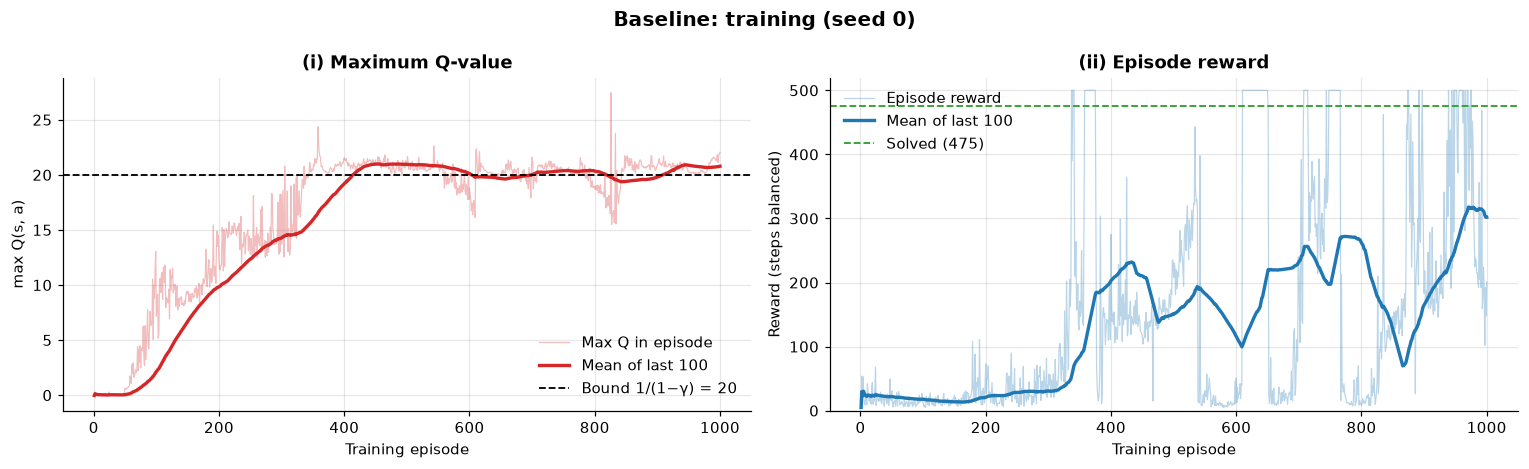

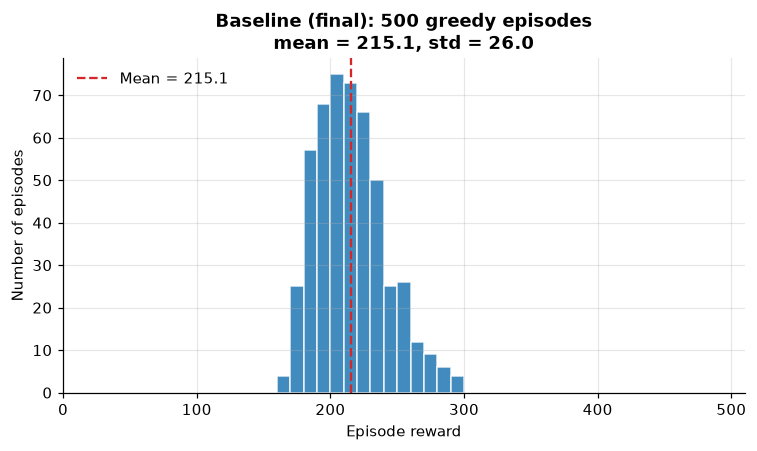

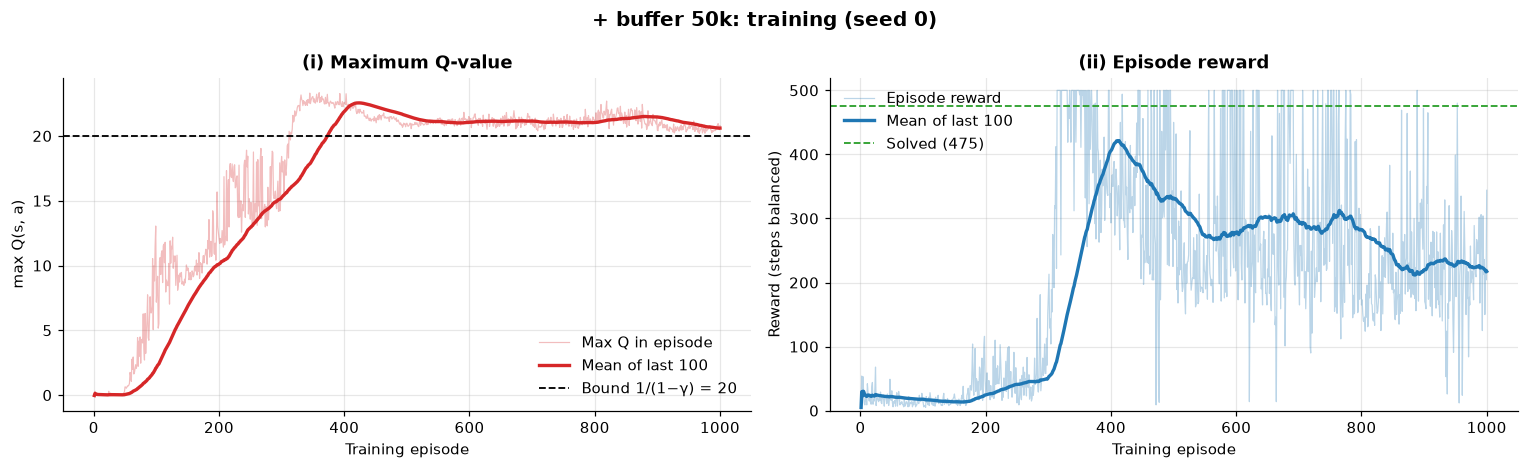

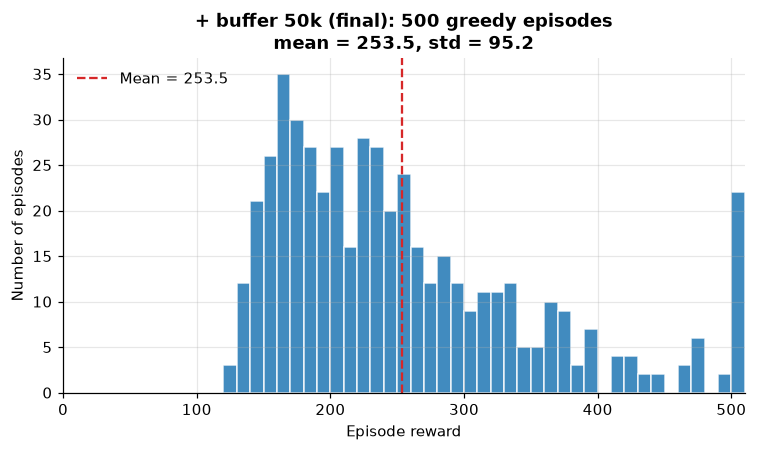

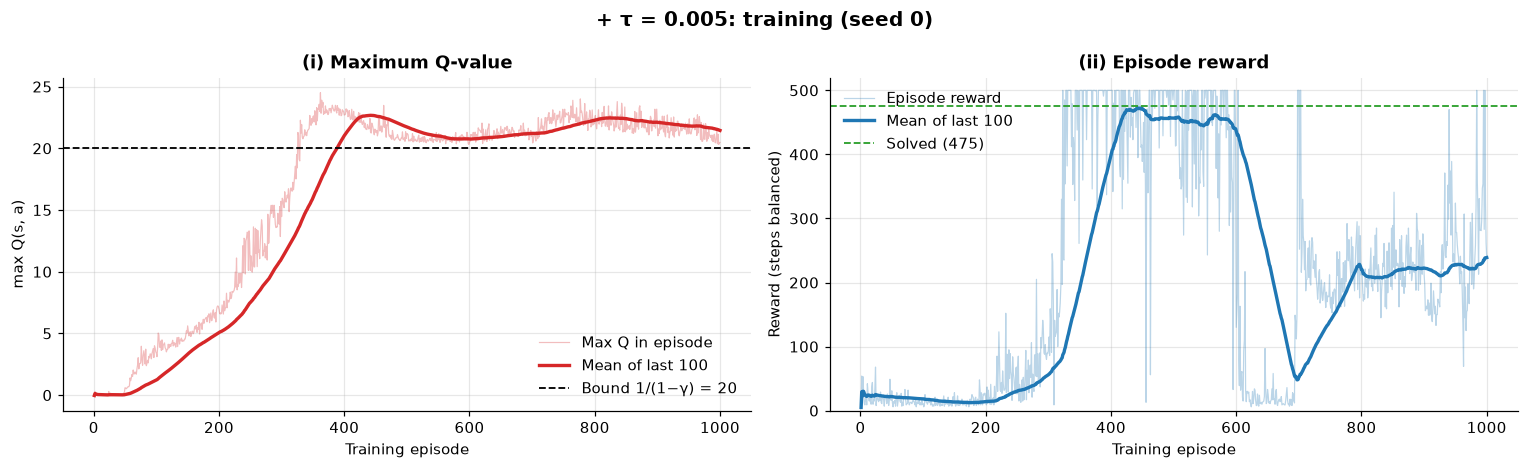

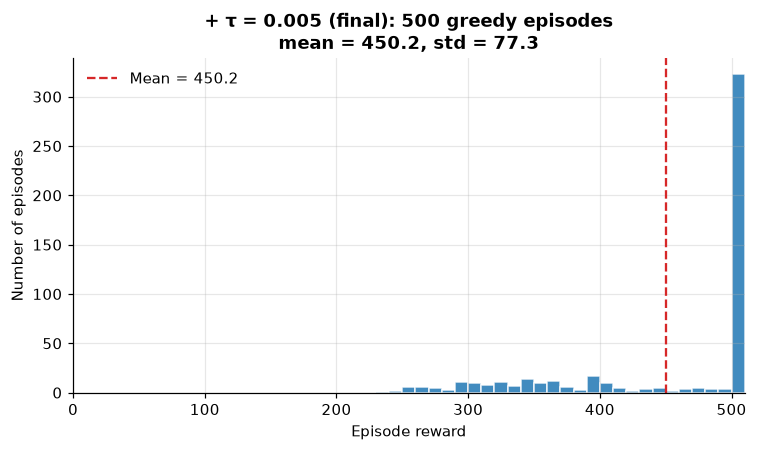

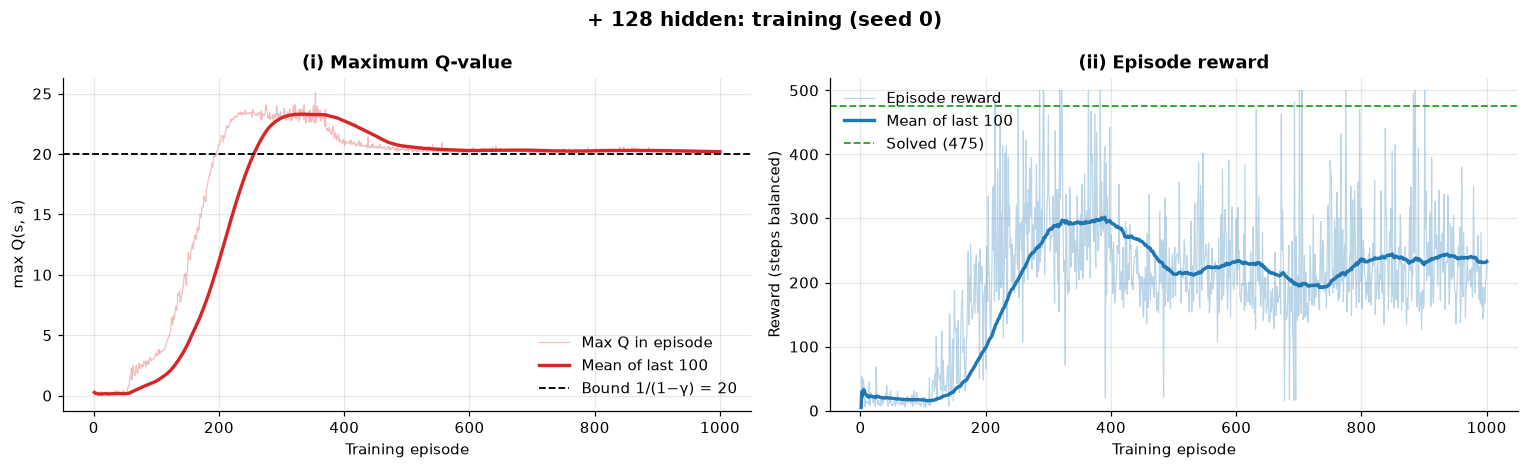

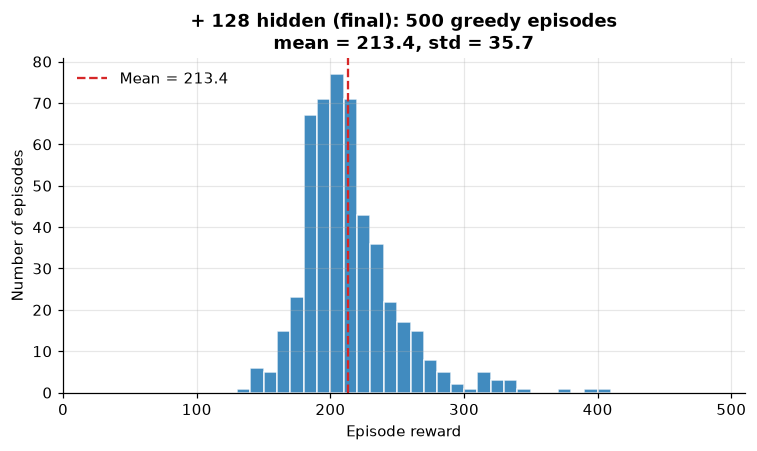

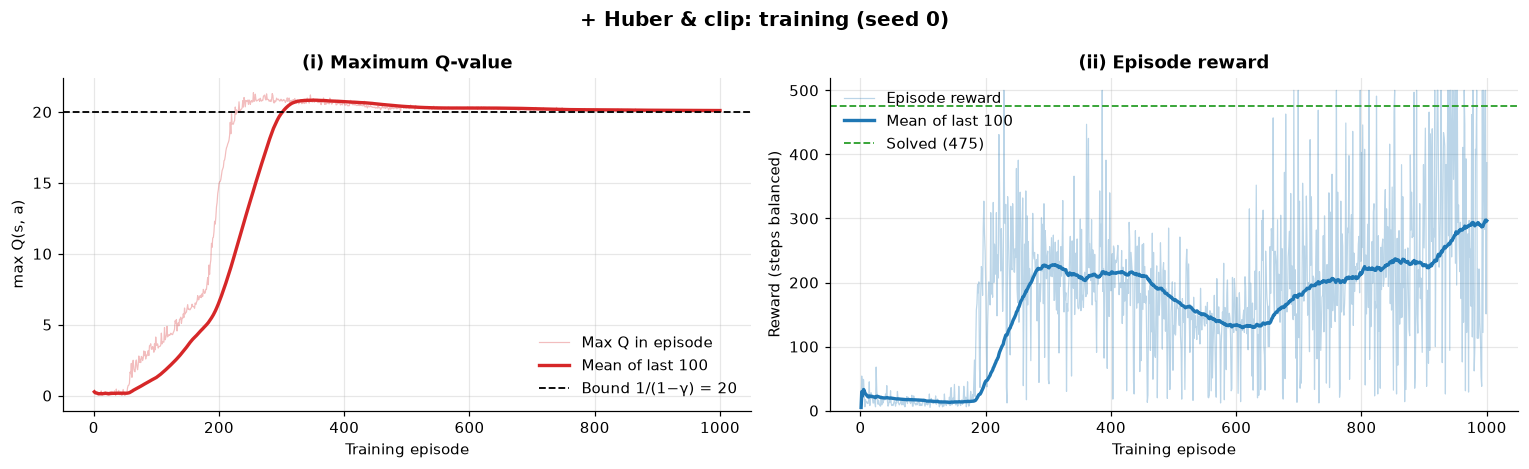

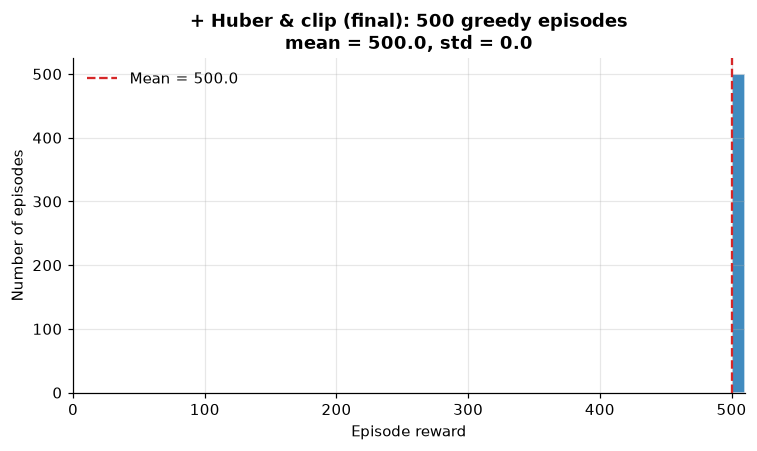

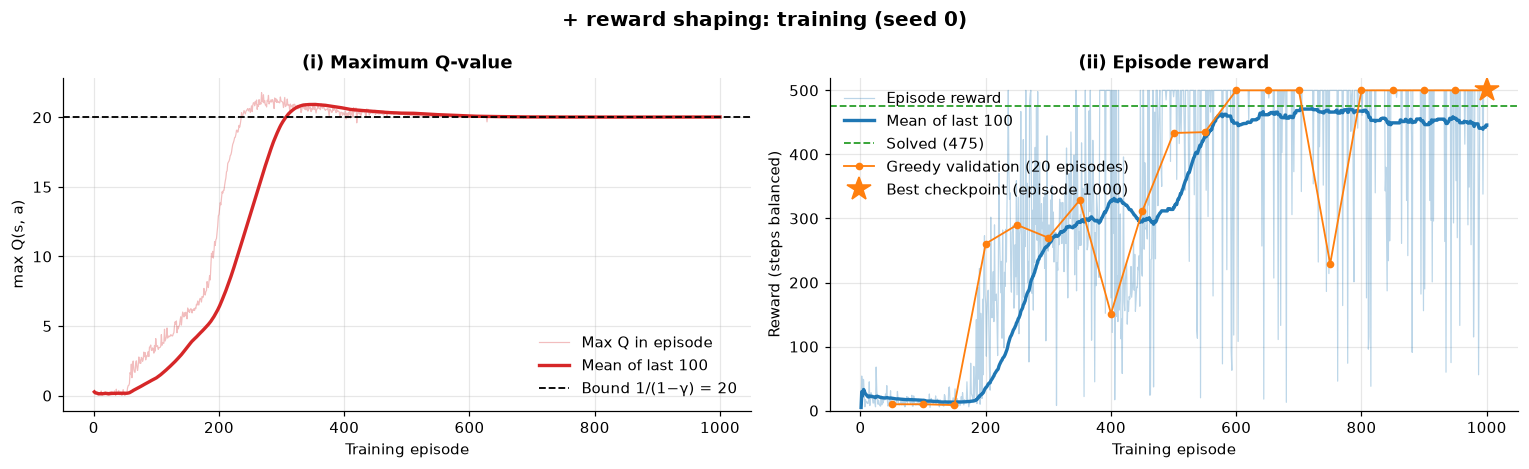

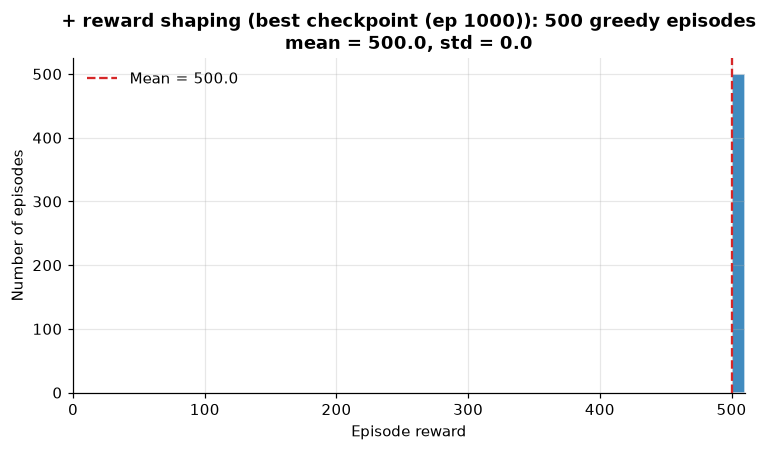

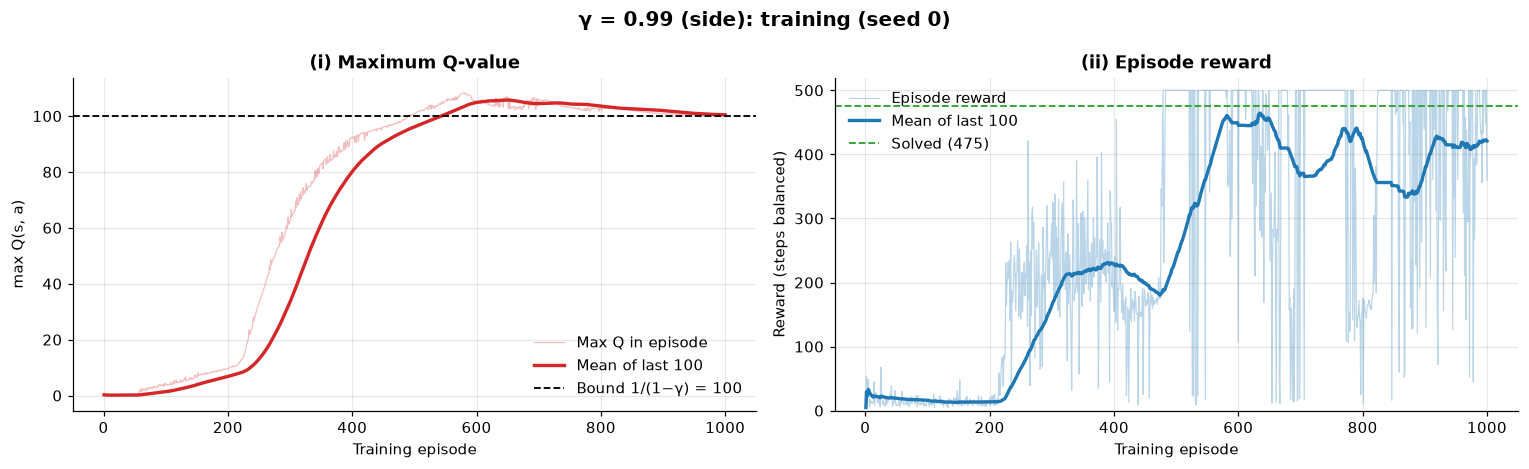

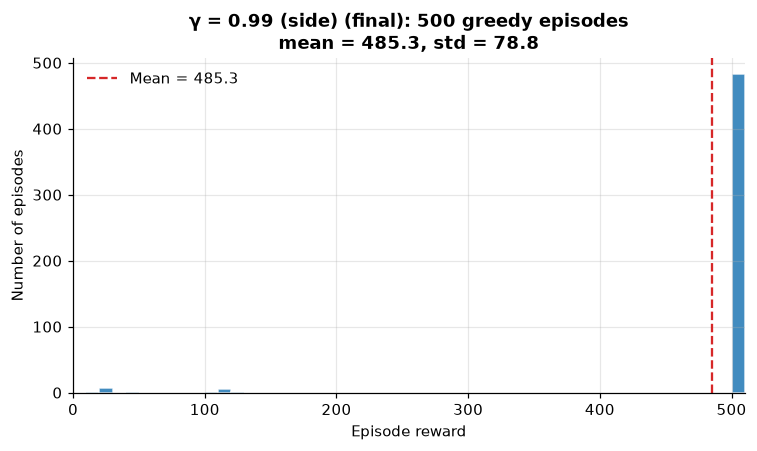

In [10]:
for name, r in RUNS.items():
    plot_training(r)
    plot_histogram(r, EVALS[name])

In [11]:
print_table(
    [summary_row(r, EVALS[name], EVALS_FINAL.get(name)) for name, r in RUNS.items()]
)

Variant           Solved at  Train mean  Last 100  Evaluated                  Eval mean ± std  Eval = 500  Eval of final weights  Max Q (last 100)
----------------  ---------  ----------  --------  -------------------------  ---------------  ----------  ---------------------  ----------------
Baseline          —          149.9       302.0     final                      215.1 ± 26.0     0%          (same)                 20.8            
+ buffer 50k      —          212.3       217.3     final                      253.5 ± 95.2     4%          (same)                 20.6            
+ τ = 0.005       —          211.5       238.9     final                      450.2 ± 77.3     65%         (same)                 21.5            
+ 128 hidden      —          202.8       232.8     final                      213.4 ± 35.7     0%          (same)                 20.2            
+ Huber & clip    —          172.6       296.4     final                      500.0 ± 0.0      100%        (same)     

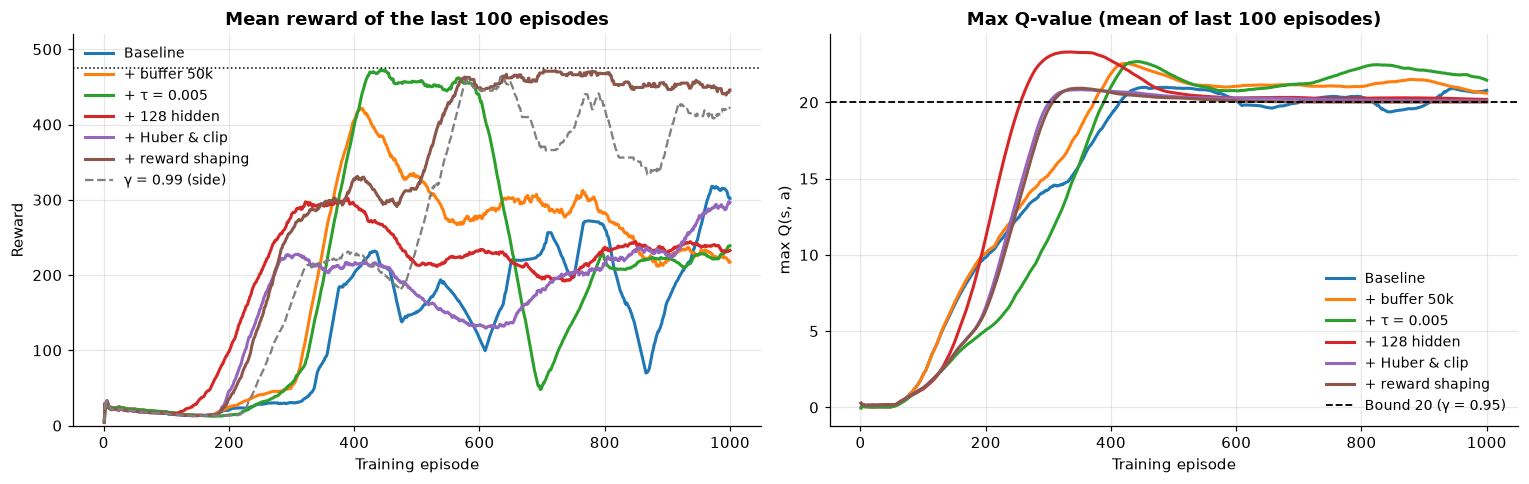

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for i, c in enumerate(LADDER):
    r = RUNS[c.name]
    ep = np.arange(1, c.episodes + 1)
    ax1.plot(ep, trailing_mean(r.log["reward"]), color=COLORS[i], lw=2, label=c.label)
    ax2.plot(ep, trailing_mean(r.log["max_q"]), color=COLORS[i], lw=2, label=c.label)
r = RUNS[SIDE_GAMMA.name]
ax1.plot(
    np.arange(1, SIDE_GAMMA.episodes + 1),
    trailing_mean(r.log["reward"]),
    color="gray",
    ls="--",
    lw=1.5,
    label=SIDE_GAMMA.label,
)
ax1.axhline(SOLVED, color="black", ls=":", lw=1)
ax2.axhline(q_bound(GAMMA), color="black", ls="--", lw=1.2, label="Bound 20 (γ = 0.95)")
ax1.set(
    title="Mean reward of the last 100 episodes",
    xlabel="Training episode",
    ylabel="Reward",
    ylim=(0, 520),
)
ax2.set(
    title="Max Q-value (mean of last 100 episodes)",
    xlabel="Training episode",
    ylabel="max Q(s, a)",
)
ax1.legend(loc="upper left", fontsize=9)
ax2.legend(loc="lower right", fontsize=9)
fig.tight_layout()
save_figure(fig, "variants_comparison")
plt.show()

**Result.**
- **Greedy evaluation.** v4 and v5 are perfect: 500 ± 0, with all 500 start states reaching the time limit. v5 is the best configuration (next cell).
- **Training curve.** No variant reaches the "solved" line (MA100 ≥ 475) during training. v5 gets closest, with 445.9 over the last 100 episodes. Exploration is not the reason, because $\epsilon \approx 0.017$ at the end and v5 still scores 494 with $\epsilon = 0.05$ in Test 7. The reason is that the policy changes with every gradient step: v5's greedy validation drops to 151 (episode 400) and 229 (episode 750) between perfect evaluations. The training MA100 therefore averages over many slightly different policies. **We judge "solved" by the greedy evaluation of the reported network, not by the training curve.**
- **Ladder steps.**
  - The ladder does not improve at every step: v2 reaches 450.2, v3 drops to 213.4, and v4 reaches 500.
  - The bigger network alone made things worse, with 767 cart failures in training (Test 8). It only paid off together with Huber loss and gradient clipping.
  - With one seed per variant, single steps are noisy: the baseline ranges from 13.8 to 215.1 across seeds (Section 4).
- **Reward shaping (v5) speeds up learning.** Compared with v4, the training mean rises from 172.6 to 323.4 and the last-100 mean from 296.4 to 445.9.
- **Best checkpoint.** The best checkpoint of v5 is episode 1000, the final weights. The validation reached 20/20 several times, and ties prefer the later episode. Checkpoint selection was not needed for seed 0, since the final weights also score 500.
- **Max Q.** For every $\gamma = 0.95$ variant, max Q settles at ≈ 20, the bound $1/(1-\gamma)$. The $\gamma = 0.99$ run settles at ≈ 100, which is its own bound.

**Best configuration.** Among the $\gamma = 0.95$ variants, the best one has the highest greedy evaluation mean (ties broken by the mean of the last 100 training episodes). Its evaluated network (`BEST.model`: the best checkpoint if it has one) is the reported final model and the reference for the seed study and the tests.

Best configuration: + reward shaping (v5_shaping), evaluated network: best checkpoint (ep 1000)


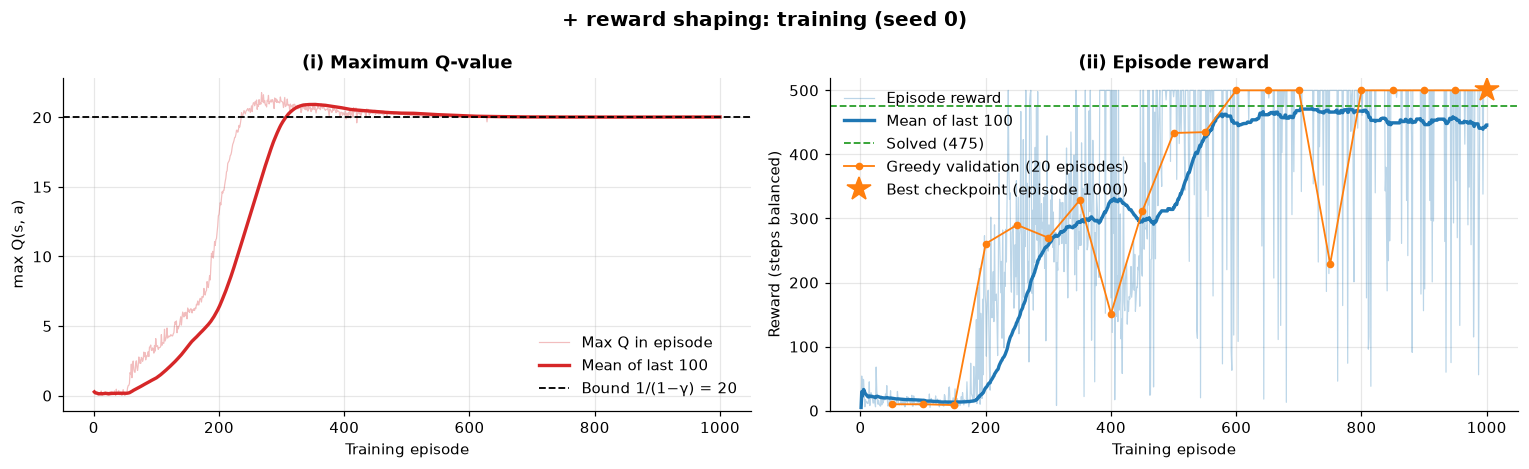

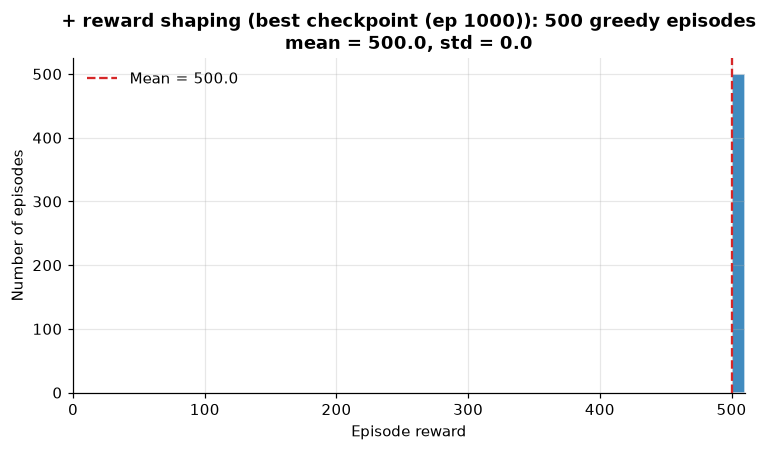

In [13]:
BEST = max(
    (RUNS[c.name] for c in LADDER),
    key=lambda r: (
        EVALS[r.config.name]["lengths"].mean(),
        r.log["reward"][-WINDOW:].mean(),
    ),
)
print(
    f"Best configuration: {BEST.config.label} ({BEST.config.name}), evaluated network: {BEST.model_label}"
)
plot_training(BEST, "training_best")
plot_histogram(BEST, EVALS[BEST.config.name], "histogram_best")

**Result.** The best configuration is **v5 (+ reward shaping)**, evaluated with its best checkpoint, which here is the final weights from episode 1000. All 500 greedy episodes reach the time limit: mean 500.0, std 0.0. A std of 0 is not a bug: every episode is truncated at 500 steps (see Test 7 for harder conditions).

## 4. Robustness Across Seeds

One run can be lucky. The baseline and the best configuration are trained with seeds 0, 1, 2 (seed 0 is reused from above); every evaluated network (best checkpoint where available) is tested on the same 500 start states.

+ reward shaping (seed 1):   0%|          | 0/1000 [00:00<?, ?it/s]

+ reward shaping (seed 2):   0%|          | 0/1000 [00:00<?, ?it/s]

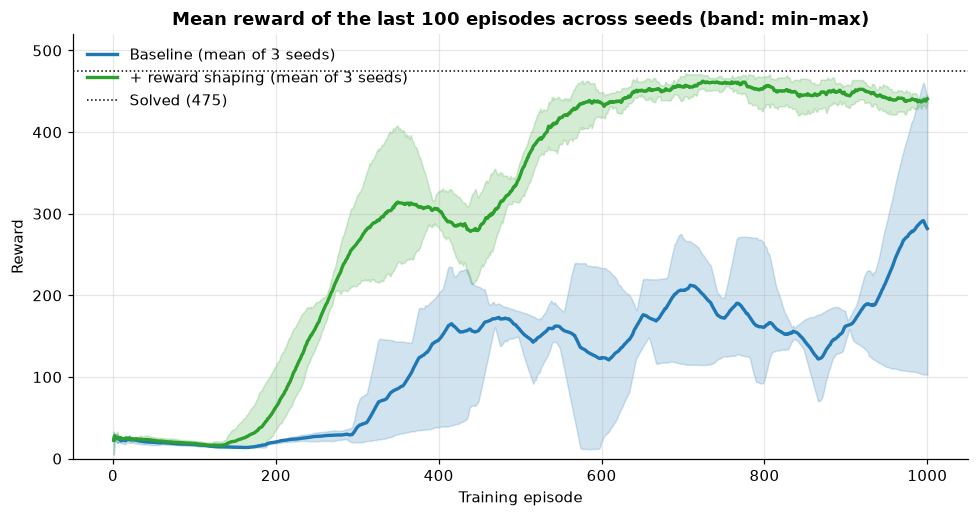

Variant           Solved at (per seed)  Last 100       Evaluated        Eval mean (per seed)  Seeds with eval = 500
----------------  --------------------  -------------  ---------------  --------------------  ---------------------
Baseline          —, —, —               281.9 ± 138.7  final            215.1, 13.8, 157.6    0/3                  
+ reward shaping  —, —, —               440.8 ± 4.7    best checkpoint  500.0, 500.0, 500.0   3/3                  


In [14]:
SEED_RUNS = {c.name: [run(c, seed) for seed in SEEDS] for c in (BASELINE, BEST.config)}
SEED_EVALS = {
    name: [evaluate(r.model) for r in runs] for name, runs in SEED_RUNS.items()
}

fig, ax = plt.subplots(figsize=(9, 4.8))
for i, (name, runs) in enumerate(SEED_RUNS.items()):
    curves = np.array([trailing_mean(r.log["reward"]) for r in runs])
    ep = np.arange(1, curves.shape[1] + 1)
    color = COLORS[0] if i == 0 else COLORS[2]
    ax.plot(
        ep,
        curves.mean(axis=0),
        color=color,
        lw=2.2,
        label=f"{runs[0].config.label} (mean of {len(runs)} seeds)",
    )
    ax.fill_between(ep, curves.min(axis=0), curves.max(axis=0), color=color, alpha=0.2)
ax.axhline(SOLVED, color="black", ls=":", lw=1, label="Solved (475)")
ax.set(
    title="Mean reward of the last 100 episodes across seeds (band: min–max)",
    xlabel="Training episode",
    ylabel="Reward",
    ylim=(0, 520),
)
ax.legend(loc="upper left")
fig.tight_layout()
save_figure(fig, "seeds")
plt.show()

rows = []
for name, runs in SEED_RUNS.items():
    last100 = np.array([r.log["reward"][-WINDOW:].mean() for r in runs])
    evals = np.array([ev["lengths"].mean() for ev in SEED_EVALS[name]])
    rows.append(
        {
            "Variant": runs[0].config.label,
            "Solved at (per seed)": ", ".join(
                str(episodes_to_solve(r.log["reward"]) or "—") for r in runs
            ),
            "Last 100": f"{last100.mean():.1f} ± {last100.std():.1f}",
            "Evaluated": runs[0].model_label.split(" (")[0],
            "Eval mean (per seed)": ", ".join(f"{e:.1f}" for e in evals),
            "Seeds with eval = 500": f"{sum((ev['lengths'] == MAX_STEPS).all() for ev in SEED_EVALS[name])}/{len(runs)}",
        }
    )
print_table(rows)

**Result.**
- **v5 is robust.** All three seeds reach 500.0 in the greedy evaluation. Their last-100 training means are almost identical (440.8 ± 4.7).
- **The baseline is not.** Its seeds evaluate to 215.1, 13.8 and 157.6. Seed 1 collapsed to 13.8, which is worse than the random policy (19.8).
- **No seed reaches MA100 ≥ 475 in training**, for the reason explained in Section 3.

## 5. Non-Standard Plot: Phase Portraits

Each panel shows one greedy episode from the **same start state** in the two phase planes of CartPole: pole angle vs. angular velocity (top) and cart position vs. cart velocity (bottom). The line is colored by time step; the red areas are the failure regions ($|\theta| > 0.21$ rad, $|x| > 2.4$), a red × marks a failure, the black dot the start. A "staircase" in the bottom row means the cart moves at an almost constant velocity, i.e. it drifts. The first figure follows the best run through training (plus its best checkpoint), the second compares the evaluated networks of all variants.

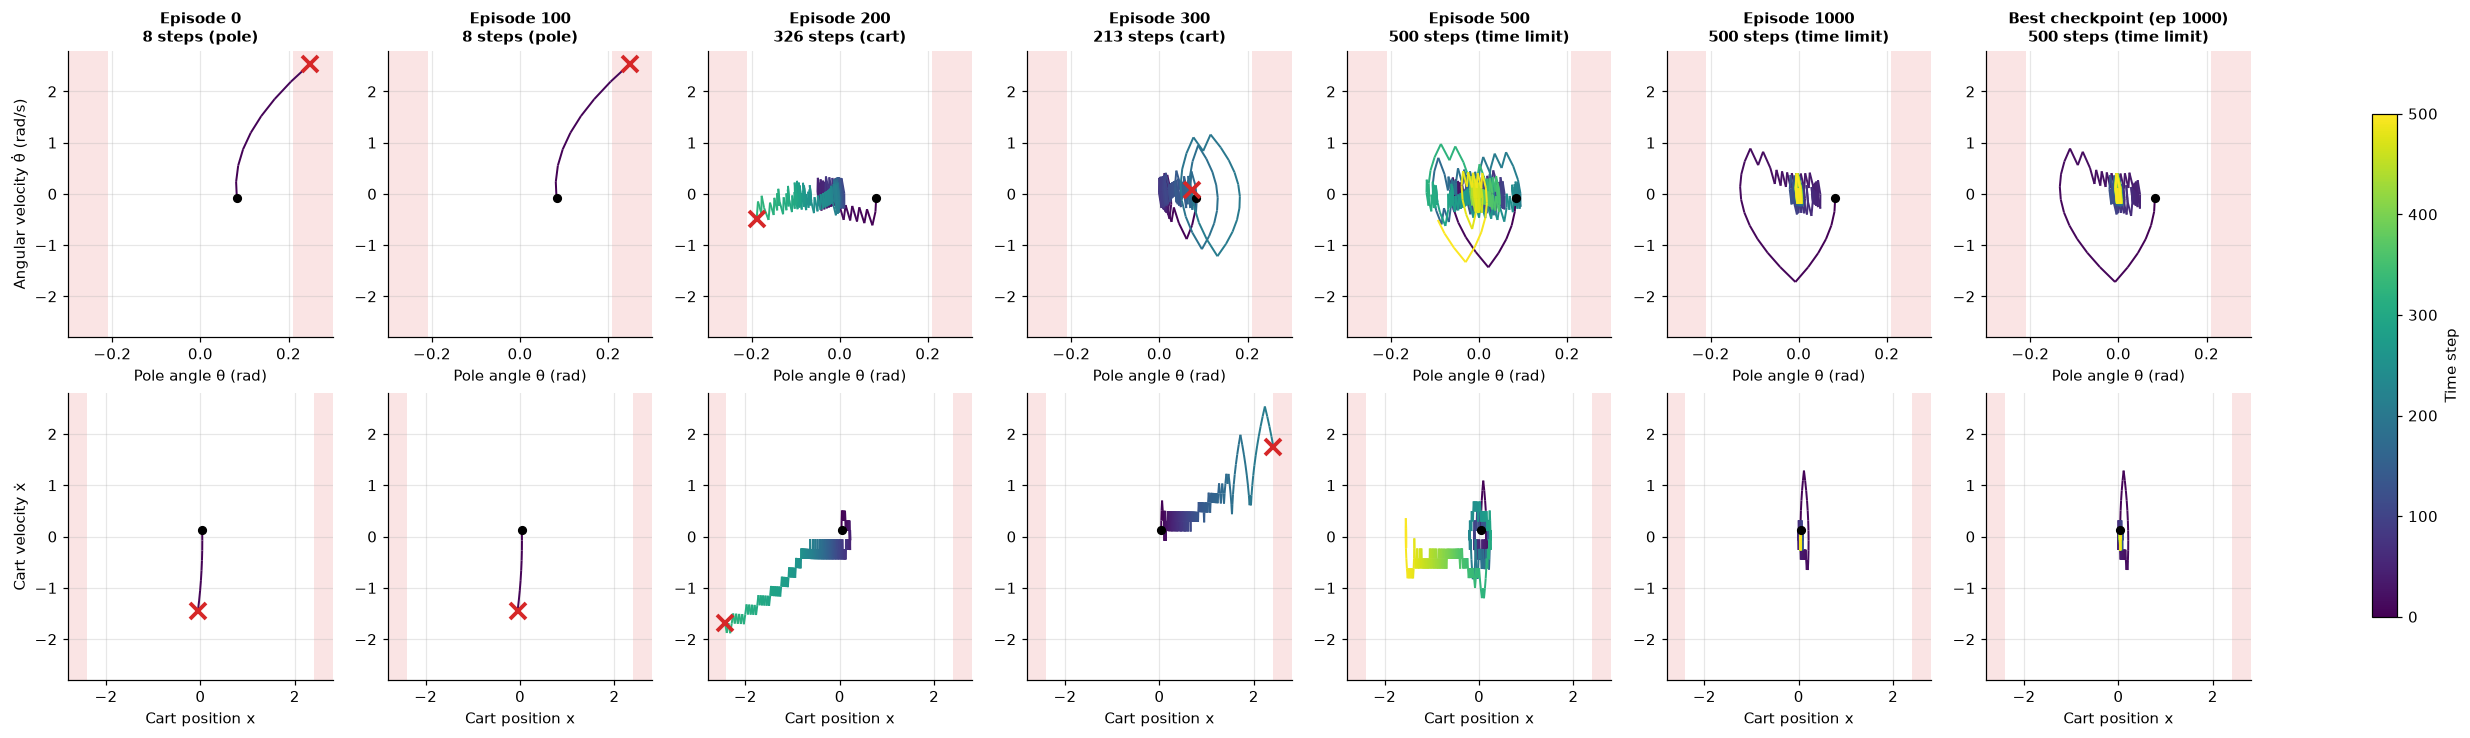

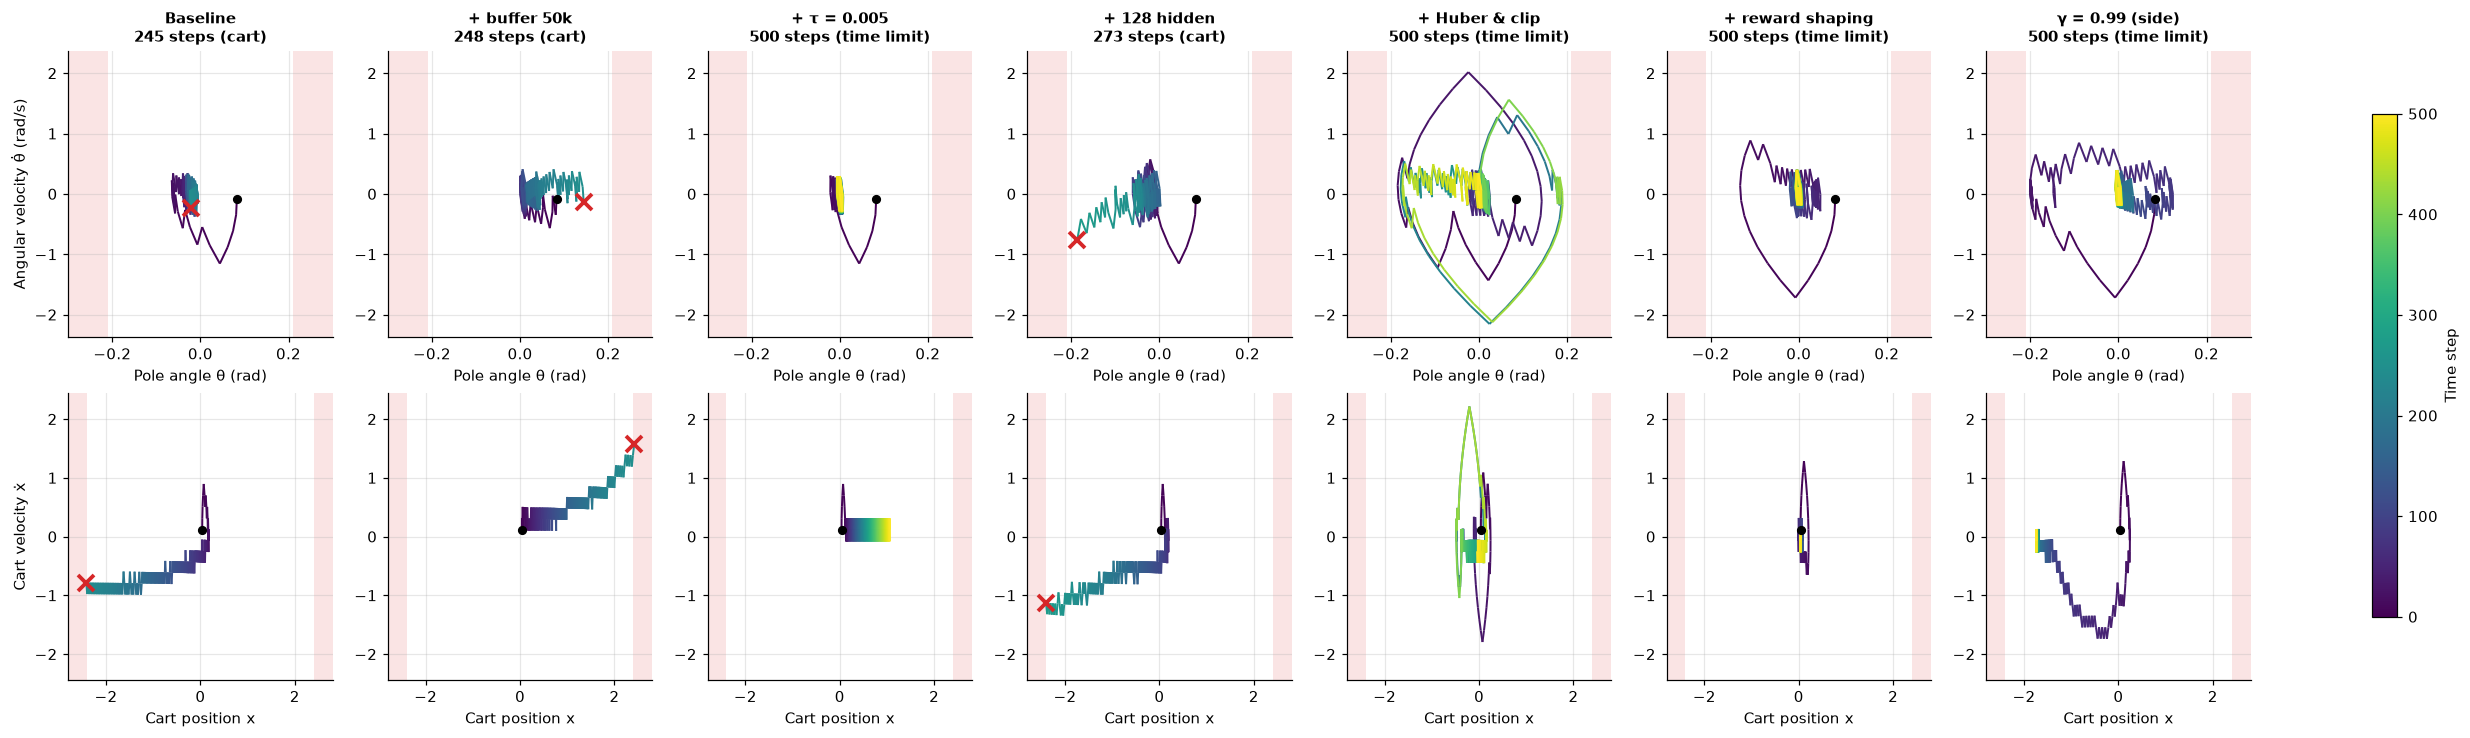

In [15]:
def colored_line(ax, x, y, c, cmap, norm) -> None:
    points = np.column_stack([x, y]).reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    lc = LineCollection(segments, cmap=cmap, norm=norm, linewidth=1.3)
    lc.set_array(c[:-1])
    ax.add_collection(lc)


def phase_portrait(
    nets: list[tuple[str, nn.Module]], name: str, seed: int = PHASE_SEED
) -> None:
    cmap, norm = plt.cm.viridis, plt.Normalize(0, MAX_STEPS)
    rollouts = [rollout(net, seed, record=True) for _, net in nets]
    trajectories = [np.vstack([r["states"], r["final_state"]]) for r in rollouts]
    planes = [  # (x index, y index, failure limit, x label, y label, x range)
        (2, 3, THETA_LIMIT, "Pole angle θ (rad)", "Angular velocity θ̇ (rad/s)", 0.3),
        (0, 1, X_LIMIT, "Cart position x", "Cart velocity ẋ", 2.8),
    ]
    fig, axes = plt.subplots(
        2,
        len(nets),
        figsize=(3.2 * len(nets), 6.6),
        squeeze=False,
        constrained_layout=True,
    )
    for row, (ix, iy, limit, xlabel, ylabel, xrange) in enumerate(planes):
        y_max = 1.1 * max(np.abs(S[:, iy]).max() for S in trajectories)
        for col, ((title, _), r, S) in enumerate(zip(nets, rollouts, trajectories)):
            ax = axes[row, col]
            ax.axvspan(-xrange, -limit, color=COLORS[3], alpha=0.12, lw=0)
            ax.axvspan(limit, xrange, color=COLORS[3], alpha=0.12, lw=0)
            colored_line(ax, S[:, ix], S[:, iy], np.arange(len(S)), cmap, norm)
            ax.plot(S[0, ix], S[0, iy], "o", color="black", ms=5)
            if r["end"] != "time limit":
                ax.plot(S[-1, ix], S[-1, iy], "x", color=COLORS[3], ms=10, mew=2.5)
            ax.set(xlim=(-xrange, xrange), ylim=(-y_max, y_max), xlabel=xlabel)
            if col == 0:
                ax.set_ylabel(ylabel)
            if row == 0:
                ax.set_title(f"{title}\n{r['length']} steps ({r['end']})", fontsize=10)
    fig.colorbar(
        ScalarMappable(norm=norm, cmap=cmap), ax=axes, label="Time step", shrink=0.8
    )
    save_figure(fig, name)
    plt.show()


training_nets = [(f"Episode {e}", BEST.net_at(e)) for e in BEST.snapshot_episodes()]
if BEST.best_net is not None:
    training_nets.append(
        (f"Best checkpoint (ep {int(BEST.log['best_episode'])})", BEST.best_net)
    )
phase_portrait(training_nets, "phase_portrait_training")
phase_portrait(
    [(RUNS[c.name].config.label, RUNS[c.name].model) for c in LADDER + [SIDE_GAMMA]],
    "phase_portrait_variants",
)

**Result (training of v5, top figure).**
- **Episodes 0 and 100.** The trajectory runs almost straight into the failure region, and the pole falls after 8 steps.
- **Episodes 200 and 300.** The pole is balanced: there is a tight zig-zag around $\theta = 0$ in the top row. The cart, however, moves in a "staircase" towards the edge (bottom row) and leaves the track after 326 and 213 steps. This is the short-horizon problem of $\gamma = 0.95$ made visible.
- **Episode 500.** The policy reaches 500 steps, but the cart still wanders to $x \approx -1.6$.
- **Episode 1000 (= best checkpoint).** After one large initial swing (the loop in the top row), the pole stays in a small region around 0. The cart never leaves $|x| < 0.3$.

**Variants (bottom figure).** The variants differ mainly in the bottom row, i.e. in how far the cart drifts. The median of the largest $|x|$ over the 500 evaluation episodes (Test 8) is:

| Variant | Median max $\lvert x \rvert$ |
|---|---|
| Baseline, + 128 hidden | 2.41 (off the track) |
| γ = 0.99 | 1.74 |
| + τ = 0.005 | 1.18 |
| + Huber & clip | 0.39 |
| + reward shaping | 0.15 |

## 6. Edge Cases

| Edge case | Handling | Checked in |
|---|---|---|
| **Termination vs. truncation** at the 500-step time limit | Only `terminated` is stored as the done flag. A truncated episode still has a future, so its last transition is bootstrapped. | Test 1c: Q at the last step of truncated episodes stays ≈ 20, not ≈ 1 |
| **Terminal mask** $(1 - \text{done})$ | The target of a terminal transition is only $r$: there is no next state, so $Q(s')$ must not be added. | Tests 2 and 3c |
| **Gradients through the target** | Targets are computed under `torch.no_grad()`, the Polyak update is outside autograd, so only the online network is trained. | Code; Test 4 |
| **Overestimation bias** of $\max_a Q$ | Double DQN (online net selects, target net evaluates) + slow target network. Q is bounded by $1/(1-\gamma) = 20$. | Max-Q plots vs. the bound; Test 4 (without a target network Q diverges) |
| **Replay warm-up** | No update before the buffer holds `learning_starts` = 1,000 transitions (≥ batch size). With a 50k buffer, waiting for a *full* buffer would delay learning by 100+ episodes. | Code |
| **Buffer too small** | A 2k buffer only holds the last 4–10 episodes; once the agent is good, it forgets failure states. | Ladder v0 → v1 |
| **Short horizon** ($\gamma = 0.95$) | The cart drifting off the track is barely visible within ~20–60 effective steps. | Test 8, phase portraits, $\gamma = 0.99$ side run, v5 |
| **Reward shaping must not make failing attractive** | The shaped reward $1 - (x'/2.4)^2$ is clipped at 0, so it is $\geq 0$ on the whole track: surviving longer never lowers the return, and Q stays $\leq 20$. Only used for learning; all plots and tables use the environment reward. | Code; max-Q plot of v5 |
| **Checkpoint selection must not use the test set** | The best checkpoint is chosen on 20 validation start states (seeds 100,000+), the reported evaluation uses seeds 0–499. | `VAL_SEED`; v5 table lists both the best checkpoint and the final weights |
| **Exploration** | $\epsilon$ decays per episode from 1 to 0.01 (never 0 during training); evaluation is greedy ($\epsilon = 0$). | Test 7 ($\epsilon = 0.05$) |
| **Saturated evaluation** | 500.0 ± 0.0 means "every episode reached the time limit", not a bug. Harder evaluations still separate the variants. | Test 7 |
| **Start states** | ±0.15 instead of the default ±0.05 for training and evaluation, same as hw-1; ±0.2 in Test 7. | Test 7 |
| **Moving average at the start** | The first 99 episodes average over fewer episodes; "solved at" only counts full 100-episode windows. | `episodes_to_solve` |
| **Stale cached runs** | A cached run is only reused if its saved config equals the current config (fields added later count as their default). | `run()`, `same_config()` |
| **Reproducibility** | Python, NumPy and PyTorch RNGs and the first `env.reset` are seeded. | Test 9 |

## 7. Validation Tests

Every test prints `[PASS]` or `[FAIL]` with the measured numbers; the summary at the end lists all of them. Tests that need the learning reward (1, 4, 5) use the reward the network was trained on, i.e. the shaped reward if the best configuration is v5.

In [16]:
CHECKS: list[tuple[str, bool]] = []


def check(name: str, passed: bool, detail: str = "") -> None:
    CHECKS.append((name, bool(passed)))
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}" + (f": {detail}" if detail else "")
    )


def returns_to_go(config: Config, r: dict) -> np.ndarray:
    """Discounted return-to-go of a recorded roll-out, using the learning reward of `config`."""
    next_states = np.vstack([r["states"][1:], r["final_state"]])
    rewards = np.array([shaped_reward(config, 1.0, s) for s in next_states])
    returns, g = np.zeros(len(rewards)), 0.0
    for t in reversed(range(len(rewards))):
        g = rewards[t] + config.gamma * g
        returns[t] = g
    return returns

### Test 1: Q-values vs. actual discounted returns (calibration)

**What:** For a state from which the episode **terminates after $k$ more steps**, the actual discounted return is known exactly. With reward +1 per step it is $G = (1-\gamma^k)/(1-\gamma)$: exactly 1 for the last step before a failure and close to 20 for $k \geq 100$ (with shaping, it is computed from the shaped rewards of the roll-out). We roll out the trained networks with exploration noise ($\epsilon \in \{0.1, 0.25, 0.5\}$, start states ±0.2) to produce failures, and compare the predicted $Q(s_t, a_t)$ (blue dots) with $G$ (black line).

**Criteria:** (a) Q right before a failure ($k = 1$) < 5, (b) correlation of Q and $G$ > 0.7, (c) Q at the last step of a **truncated** episode > 15 (the state still has a future), (d) mean Q of long-lived states ($k \geq 100$) within 25 % of the bound of their actual return.

[FAIL] T1a Baseline: Q right before a failure is small: mean Q(k=1) = 14.10 (actual return ≤ 1), 300 failures
[PASS] T1b Baseline: Q correlates with the actual return: r = 0.779
[INFO] T1c Baseline: no truncated episode in the noisy roll-outs
[PASS] T1d Baseline: no runaway overestimation: mean Q(k ≥ 100) = 21.36, actual return 19.98
[FAIL] T1a + reward shaping: Q right before a failure is small: mean Q(k=1) = 13.30 (actual return ≤ 1), 186 failures
[FAIL] T1b + reward shaping: Q correlates with the actual return: r = 0.492
[PASS] T1c + reward shaping: truncation is bootstrapped (Q stays high): mean Q at truncation = 19.99 over 114 episodes
[PASS] T1d + reward shaping: no runaway overestimation: mean Q(k ≥ 100) = 19.95, actual return 19.92


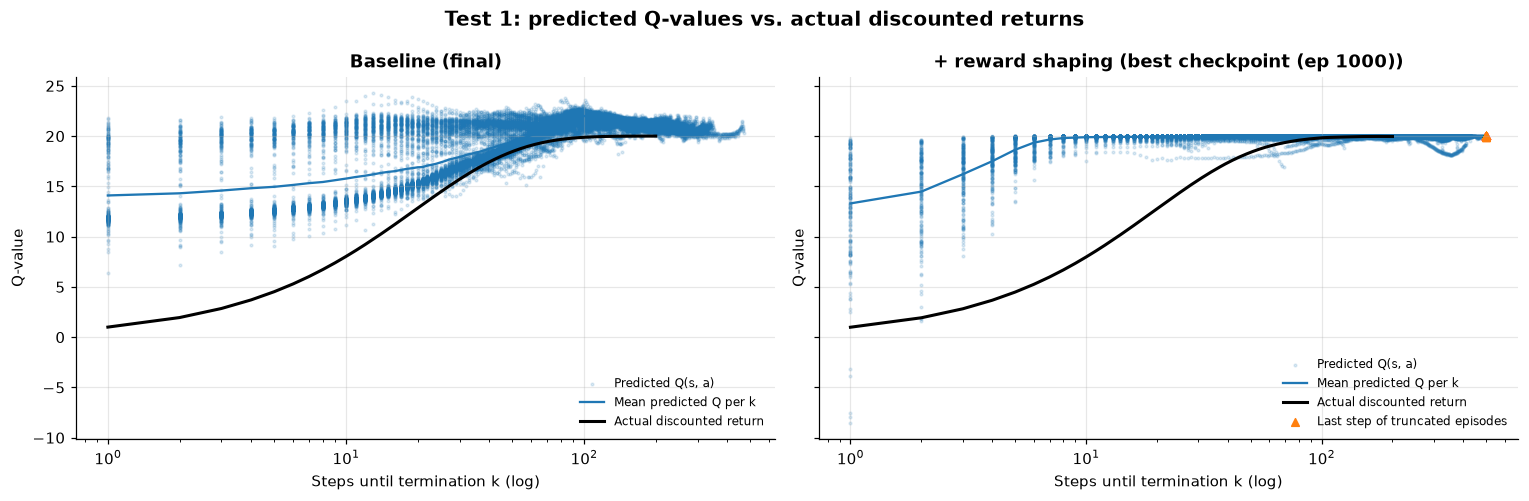

In [17]:
def calibration_data(net: nn.Module, config: Config, n: int = 100) -> dict:
    ks, qs, gs, truncated_q = [], [], [], []
    for eps in (0.1, 0.25, 0.5):
        for i in range(n):
            r = rollout(net, 50_000 + i, eps=eps, start=WIDE_START, record=True)
            q_taken = r["qs"][np.arange(r["length"]), r["actions"]]
            if r["end"] == "time limit":
                truncated_q.append(q_taken[-1])
                continue
            ks.append(
                r["length"] - np.arange(r["length"])
            )  # steps until termination, incl. the current one
            qs.append(q_taken)
            gs.append(returns_to_go(config, r))
    return {
        "k": np.concatenate(ks),
        "q": np.concatenate(qs),
        "g": np.concatenate(gs),
        "truncated_q": np.array(truncated_q),
    }


fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, r in zip(axes, (RUNS[BASELINE.name], BEST)):
    net, label = (r.model, r.config.label)
    d = calibration_data(net, r.config)
    k_unique = np.unique(d["k"])[:200]
    ax.scatter(
        d["k"], d["q"], s=3, alpha=0.15, color=COLORS[0], label="Predicted Q(s, a)"
    )
    ax.plot(
        k_unique,
        [d["q"][d["k"] == k].mean() for k in k_unique],
        color=COLORS[0],
        lw=1.5,
        label="Mean predicted Q per k",
    )
    ax.plot(
        k_unique,
        [d["g"][d["k"] == k].mean() for k in k_unique],
        color="black",
        lw=2,
        label="Actual discounted return",
    )
    if d["truncated_q"].size:
        ax.scatter(
            np.full(d["truncated_q"].size, MAX_STEPS),
            d["truncated_q"],
            marker="^",
            color=COLORS[1],
            s=25,
            label="Last step of truncated episodes",
        )
    ax.set(
        xscale="log",
        title=f"{label} ({r.model_label})",
        xlabel="Steps until termination k (log)",
        ylabel="Q-value",
    )
    ax.legend(loc="lower right", fontsize=8)

    q_last = d["q"][d["k"] == 1]
    check(
        f"T1a {label}: Q right before a failure is small",
        q_last.mean() < 5,
        f"mean Q(k=1) = {q_last.mean():.2f} (actual return ≤ 1), {q_last.size} failures",
    )
    corr = np.corrcoef(d["q"], d["g"])[0, 1]
    check(
        f"T1b {label}: Q correlates with the actual return",
        corr > 0.7,
        f"r = {corr:.3f}",
    )
    if d["truncated_q"].size:
        check(
            f"T1c {label}: truncation is bootstrapped (Q stays high)",
            d["truncated_q"].mean() > 15,
            f"mean Q at truncation = {d['truncated_q'].mean():.2f} over {d['truncated_q'].size} episodes",
        )
    else:
        print(f"[INFO] T1c {label}: no truncated episode in the noisy roll-outs")
    long = d["k"] >= 100
    if long.any():
        q_long, g_long = d["q"][long].mean(), d["g"][long].mean()
        check(
            f"T1d {label}: no runaway overestimation",
            abs(q_long - g_long) < 0.25 * q_bound(r.config.gamma),
            f"mean Q(k ≥ 100) = {q_long:.2f}, actual return {g_long:.2f}",
        )
fig.suptitle(
    "Test 1: predicted Q-values vs. actual discounted returns",
    fontsize=13,
    fontweight="bold",
)
fig.tight_layout()
save_figure(fig, "test_q_calibration")
plt.show()

**Result.**
- **Passed checks.**
  - **Truncation is handled correctly (T1c).** Q at the last step of a truncated episode is 19.99, not 1.
  - **No runaway overestimation (T1d).** Long-lived states have Q ≈ 20, matching their actual return of ≈ 20.
- **T1a fails for both networks.** One step before a failure, the true value is ≤ 1, but the networks predict 14.1 on average (baseline) and 13.3 (v5).
  - The figure shows that v5 only "sees" a failure coming about 5 steps ahead; before that, Q stays at its plateau of 20.
  - The reason is the data, not the update rule. These near-failure states, reached with up to 50 % random actions and wide starts, are almost absent from the replay buffer of a good agent: in the 50k buffer, most transitions come from 500-step episodes. In these states, the network extrapolates its plateau value.
  - This matches Test 2, where Q is exact wherever data exists.
- **T1b fails for v5 (r = 0.49).** This is partly a limitation of the test itself:
  - $Q(s,a)$ estimates the return when the agent continues **greedily**, while $G$ is measured under the **noisy** roll-out policy.
  - For $k > 1$, it is therefore expected that $Q > G$, and the more noise, the larger the gap.
  - Only $k = 1$ (T1a) is independent of the policy. A cleaner version would add noise only for the first steps and then act greedily.
- **Takeaway: the Q-function is accurate on the states the policy visits, not on rare states at the edge of the state space.**

### Test 2: $\gamma = 0$ sanity run

**What:** With $\gamma = 0$, the target is just the immediate reward, which is always 1. A correct implementation must therefore learn $Q(s, a) = 1$ for **every** state and action, independent of the policy. This isolates the target computation from bootstrapping. The run uses the baseline configuration for 1,000 episodes (~20,000 transitions). Since all actions are worth the same, the greedy action is arbitrary, so the episode reward stays at the level of always pushing one way.

**Criterion:** on states from 50 random-policy episodes, the mean $|Q - 1|$ is below 0.05 and 95 % of the Q-values lie within $1 \pm 0.1$. (States at the edge of the visited region converge last, so we do not require it for the single worst state; the maximum is printed.)

In [18]:
GAMMA0 = replace(BASELINE, name="test_gamma0", label="γ = 0", gamma=0.0, episodes=1_000)
r_gamma0 = run(GAMMA0)
states = np.vstack(
    [rollout(None, 70_000 + i, record=True)["states"] for i in range(50)]
)
err = np.abs(q_values(r_gamma0.net, states) - 1)
check(
    "T2 γ = 0: Q = 1 for every state and action",
    err.mean() < 0.05 and np.quantile(err, 0.95) < 0.1,
    f"mean |Q−1| = {err.mean():.4f}, 95th percentile = {np.quantile(err, 0.95):.4f}, max = {err.max():.3f} on {len(states)} states",
)
print(
    f"Mean reward of the last 100 training episodes: {r_gamma0.log['reward'][-100:].mean():.1f}"
)

test_gamma0 (seed 0): saved config differs, retraining


γ = 0 (seed 0):   0%|          | 0/1000 [00:00<?, ?it/s]

[PASS] T2 γ = 0: Q = 1 for every state and action: mean |Q−1| = 0.0040, 95th percentile = 0.0104, max = 0.201 on 1112 states
Mean reward of the last 100 training episodes: 16.2


**Result.** Passed.
- **Accuracy.** Over 1,112 states, the mean $|Q - 1|$ is 0.004, and the 95th percentile is 0.010.
- **Worst state.** The maximum deviation is 0.20, on a rarely visited state at the edge of the visited region.
- **What this confirms.** The target computation and the terminal mask are correct: without bootstrapping, the network learns exactly the immediate reward.
- **Episode reward.** It stays at 16.2. This is expected, because all actions are worth the same and the greedy action is arbitrary.

### Test 3: Control experiments

**What:** Trainings with the best configuration (1,000 episodes, seed 0) that only differ in the learning signal, plus two reference policies (random; always push left). "Normal" is the best run itself.

| Training | Criterion |
|---|---|
| Normal | Learns: mean of the last 100 episodes > 2 × mean of the first 100 |
| Learning rate 0 | The weights never change (identical to the initialization), no learning (last 100 < 50) |
| Negated reward | Learns to fail as fast as possible: last 100 below the random policy, and Q < 0 |

ctrl_lr0 (seed 0): saved config differs, retraining


Learning rate 0 (seed 0):   0%|          | 0/1000 [00:00<?, ?it/s]

ctrl_negated (seed 0): saved config differs, retraining


Negated reward (seed 0):   0%|          | 0/1000 [00:00<?, ?it/s]

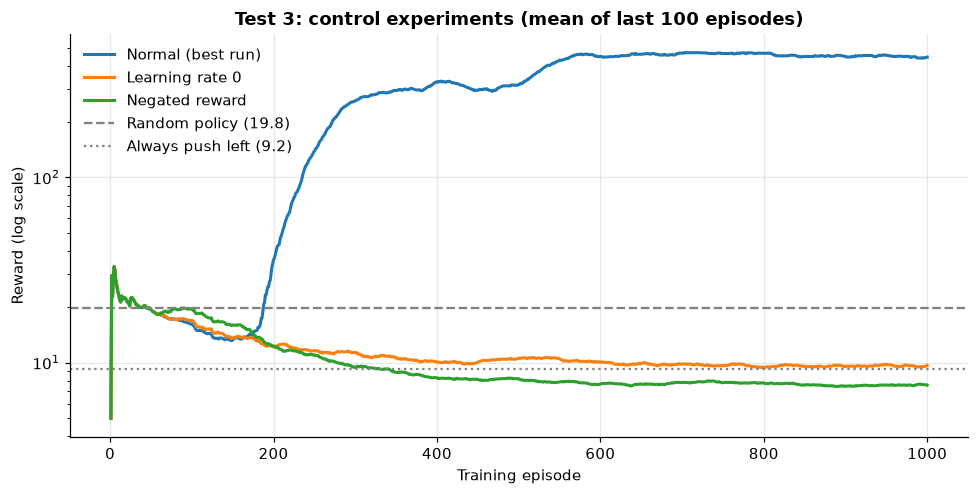

Normal (best run)  first 100:   16.1   last 100:  445.9
Learning rate 0    first 100:   16.9   last 100:    9.7
Negated reward     first 100:   19.4   last 100:    7.6
Random policy        19.8
Always left           9.2
[PASS] T3a normal training learns: 16.1 → 445.9
[PASS] T3b learning rate 0: weights unchanged, no learning: weights unchanged = True
[PASS] T3c negated reward: learns to fail fast: last 100 = 7.6, mean Q = -5.71


In [19]:
CONTROL = replace(BEST.config, eval_every=None)
controls = {
    "Normal (best run)": BEST,
    "Learning rate 0": run(
        replace(CONTROL, name="ctrl_lr0", label="Learning rate 0", lr=0.0)
    ),
    "Negated reward": run(
        replace(CONTROL, name="ctrl_negated", label="Negated reward", reward_sign=-1.0)
    ),
}
random_ref = evaluate(None)["lengths"].mean()
left_ref = evaluate(None, fixed_action=0)["lengths"].mean()

fig, ax = plt.subplots(figsize=(9, 4.6))
for i, (label, r) in enumerate(controls.items()):
    ax.plot(
        np.arange(1, r.config.episodes + 1),
        trailing_mean(r.log["reward"]),
        color=COLORS[i],
        lw=2,
        label=label,
    )
ax.axhline(random_ref, color="gray", ls="--", label=f"Random policy ({random_ref:.1f})")
ax.axhline(left_ref, color="gray", ls=":", label=f"Always push left ({left_ref:.1f})")
ax.set(
    title="Test 3: control experiments (mean of last 100 episodes)",
    xlabel="Training episode",
    ylabel="Reward (log scale)",
    yscale="log",
)
ax.legend()
fig.tight_layout()
save_figure(fig, "test_control_experiments")
plt.show()

rew = {label: r.log["reward"] for label, r in controls.items()}
for label, rewards in rew.items():
    print(
        f"{label:<18} first 100: {rewards[:100].mean():6.1f}   last 100: {rewards[-100:].mean():6.1f}"
    )
print(f"{'Random policy':<18} {random_ref:6.1f}\n{'Always left':<18} {left_ref:6.1f}")

normal = rew["Normal (best run)"]
check(
    "T3a normal training learns",
    normal[-100:].mean() > 2 * normal[:100].mean(),
    f"{normal[:100].mean():.1f} → {normal[-100:].mean():.1f}",
)
lr0 = controls["Learning rate 0"]
unchanged = all(
    torch.equal(lr0.snapshots[0][k], lr0.snapshots[lr0.config.episodes][k])
    for k in lr0.snapshots[0]
)
check(
    "T3b learning rate 0: weights unchanged, no learning",
    unchanged and rew["Learning rate 0"][-100:].mean() < 50,
    f"weights unchanged = {unchanged}",
)
q_neg = q_values(controls["Negated reward"].net, states)
check(
    "T3c negated reward: learns to fail fast",
    rew["Negated reward"][-100:].mean() < random_ref and q_neg.mean() < 0,
    f"last 100 = {rew['Negated reward'][-100:].mean():.1f}, mean Q = {q_neg.mean():.2f}",
)

**Result.** All three controls pass.
- **Normal training** improves from 16.1 to 445.9.
- **Learning rate 0** leaves the weights unchanged, and the reward stays at 9.7. That is the level of "always push left" (9.2): an untrained network happens to prefer one action in almost every state.
- **Negated reward** learns to fail fast. It ends at 7.6, below even the random policy (19.8), with mean Q = −5.71: negative, as it should be, and within the bound of −20.

So the learning signal really comes from the reward and the gradient updates.

### Test 4: Ablation of the DQN components

**What:** The best configuration retrained (1,000 episodes, seed 0) (a) as vanilla DQN (target net selects *and* evaluates the next action) and (b) without a target network ($\tau = 1$: the target equals the online network after every step). All three are compared with their final weights. We measure the **overestimation** at the start states: predicted $\max_a Q(s_0)$ minus the actual discounted return of the greedy episode from $s_0$.

**Criteria:** (a) without a target network, Q runs far beyond its bound (> 10 × 20), (b) Double DQN overestimates less than vanilla DQN.

abl_vanilla (seed 0): saved config differs, retraining


Vanilla DQN (seed 0):   0%|          | 0/1000 [00:00<?, ?it/s]

abl_no_target (seed 0): saved config differs, retraining


No target network (seed 0):   0%|          | 0/1000 [00:00<?, ?it/s]

Double DQN (best)  overestimation at s0:     +0.02   max Q (last 100):     20.02   last 100 reward:  445.9
Vanilla DQN        overestimation at s0:     +0.06   max Q (last 100):     20.03   last 100 reward:  481.5
No target network  overestimation at s0:  +3272.54   max Q (last 100):  15810.43   last 100 reward:    9.7


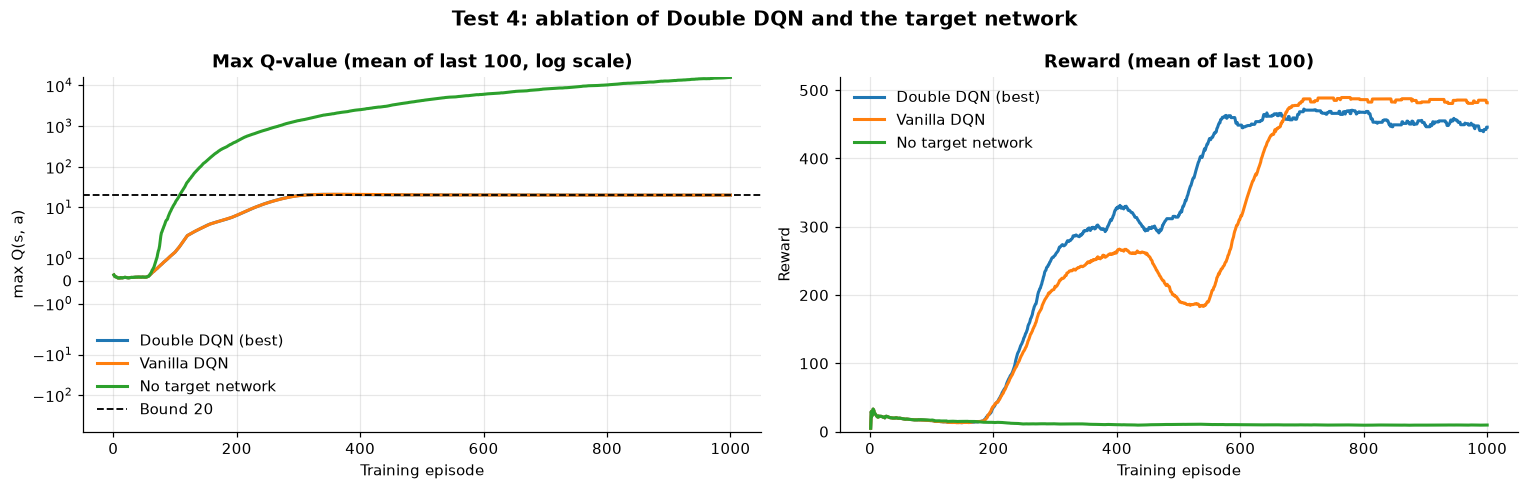

[PASS] T4a without a target network Q diverges: max Q (last 100) = 15810, bound 20
[PASS] T4b Double DQN overestimates less than vanilla DQN: Double DQN (best): +0.02, Vanilla DQN: +0.06, No target network: +3272.54


In [20]:
ABL = replace(BEST.config, eval_every=None)
ABLATIONS = {
    "Double DQN (best)": BEST,
    "Vanilla DQN": run(
        replace(ABL, name="abl_vanilla", label="Vanilla DQN", double=False)
    ),
    "No target network": run(
        replace(
            ABL, name="abl_no_target", label="No target network", double=False, tau=1.0
        )
    ),
}


def overestimation(net: nn.Module, config: Config, n: int = 100) -> float:
    gaps = []
    for i in range(n):
        r = rollout(net, i, record=True)
        gaps.append(r["qs"][0].max() - returns_to_go(config, r)[0])
    return float(np.mean(gaps))


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
over = {}
for i, (label, r) in enumerate(ABLATIONS.items()):
    ep = np.arange(1, r.config.episodes + 1)
    ax1.plot(ep, trailing_mean(r.log["max_q"]), color=COLORS[i], lw=2, label=label)
    ax2.plot(ep, trailing_mean(r.log["reward"]), color=COLORS[i], lw=2, label=label)
    over[label] = overestimation(r.net, r.config)
    print(
        f"{label:<18} overestimation at s0: {over[label]:+9.2f}   max Q (last 100): {r.log['max_q'][-100:].mean():9.2f}   last 100 reward: {r.log['reward'][-100:].mean():6.1f}"
    )
ax1.axhline(q_bound(GAMMA), color="black", ls="--", lw=1.2, label="Bound 20")
ax1.set(
    title="Max Q-value (mean of last 100, log scale)",
    xlabel="Training episode",
    ylabel="max Q(s, a)",
    yscale="symlog",
)
ax2.set(
    title="Reward (mean of last 100)",
    xlabel="Training episode",
    ylabel="Reward",
    ylim=(0, 520),
)
ax1.legend()
ax2.legend()
fig.suptitle(
    "Test 4: ablation of Double DQN and the target network",
    fontsize=13,
    fontweight="bold",
)
fig.tight_layout()
save_figure(fig, "test_ablations")
plt.show()
no_target_q = ABLATIONS["No target network"].log["max_q"][-100:].mean()
check(
    "T4a without a target network Q diverges",
    no_target_q > 10 * q_bound(GAMMA),
    f"max Q (last 100) = {no_target_q:.0f}, bound {q_bound(GAMMA):.0f}",
)
check(
    "T4b Double DQN overestimates less than vanilla DQN",
    over["Double DQN (best)"] < over["Vanilla DQN"],
    ", ".join(f"{k}: {v:+.2f}" for k, v in over.items()),
)

**Result.**
- **The target network is essential (T4a).** Without it ($\tau = 1$), Q diverges to 15,810, about 790× the bound of 20. The overestimation at $s_0$ is +3,273, and the agent does not learn at all (last-100 mean 9.7).
- **Double DQN vs. vanilla DQN (T4b).** T4b passes, but the difference is tiny: Double DQN overestimates by +0.02 and vanilla DQN by +0.06.
  - Vanilla DQN even had a higher last-100 training mean (481.5 vs. 445.9).
  - With a slow target network ($\tau = 0.005$), Q saturates at the bound of 20, so there is little room for the maximization bias.
  - **For CartPole with $\gamma = 0.95$, the target network matters; Double DQN only marginally.** With one seed, the difference between vanilla and Double DQN is within noise.

### Test 5: The first 10 steps

**What:** One greedy episode of the reported network from the evaluation start state 0. Per step: state, both Q-values, the action, the learning reward $r$ and the TD target $y = r + \gamma \max_a Q(s', a)$ computed with the same network. **Criterion:** mean |TD error| < 1 over the whole episode (the network is a fixed point of its own Bellman update).

In [21]:
r = rollout(BEST.model, 0, record=True)
S, Q, A = r["states"], r["qs"], r["actions"]
next_states = np.vstack([S[1:], r["final_state"]])
rewards = np.array([shaped_reward(BEST.config, 1.0, s) for s in next_states])
q_next = q_values(BEST.model, next_states).max(axis=1)
dones = np.zeros(len(S))
dones[-1] = float(r["end"] != "time limit")
y = rewards + GAMMA * q_next * (1 - dones)
print(
    f"{'t':>2} {'x':>7} {'ẋ':>7} {'θ':>7} {'θ̇':>7} {'Q(L)':>7} {'Q(R)':>7} {'act':>4} {'r':>6} {'y':>7} {'TD err':>7}"
)
for t in range(10):
    print(
        f"{t:>2} {S[t, 0]:7.3f} {S[t, 1]:7.3f} {S[t, 2]:7.3f} {S[t, 3]:7.3f} {Q[t, 0]:7.3f} {Q[t, 1]:7.3f} "
        f"{'R' if A[t] else 'L':>4} {rewards[t]:6.3f} {y[t]:7.3f} {Q[t, A[t]] - y[t]:+7.3f}"
    )
td = np.abs(Q[np.arange(len(S)), A] - y)
gap = np.abs(Q[:, 1] - Q[:, 0])
check(
    "T5 converged: small TD error along a greedy episode",
    td.mean() < 1.0,
    f"mean |TD error| = {td.mean():.3f} over {len(S)} steps",
)
print(
    f"Action gap |Q(R) − Q(L)| along the episode: median {np.median(gap):.4f}, mean {gap.mean():.4f}"
)

 t       x       ẋ       θ      θ̇    Q(L)    Q(R)  act      r       y  TD err
 0   0.041  -0.069  -0.138  -0.145  19.909  19.893    L  1.000  19.917  -0.007
 1   0.040  -0.262  -0.141   0.101  19.913  19.894    L  1.000  19.925  -0.012
 2   0.034  -0.455  -0.139   0.346  19.921  19.905    L  1.000  19.928  -0.006
 3   0.025  -0.648  -0.132   0.592  19.924  19.910    L  1.000  19.918  +0.006
 4   0.012  -0.841  -0.120   0.841  19.913  19.903    L  1.000  19.909  +0.004
 5  -0.004  -1.034  -0.103   1.094  19.904  19.899    L  1.000  19.902  +0.002
 6  -0.025  -1.228  -0.081   1.352  19.897  19.896    L  1.000  19.902  -0.005
 7  -0.050  -1.422  -0.054   1.619  19.892  19.897    R  0.999  19.894  +0.003
 8  -0.078  -1.226  -0.022   1.310  19.886  19.890    R  0.998  19.887  +0.003
 9  -0.103  -1.031   0.004   1.010  19.881  19.883    R  0.997  19.879  +0.003
[PASS] T5 converged: small TD error along a greedy episode: mean |TD error| = 0.001 over 500 steps
Action gap |Q(R) − Q(L)| along t

**Result.** Passed. The mean |TD error| along the 500-step episode is 0.001, so the network is a fixed point of its own Bellman update.
- **Q-values.** Both Q-values are ≈ 19.9, close to the bound.
- **Action gap.** The gap $|Q(R) - Q(L)|$ is tiny: median 0.0016. With $\gamma = 0.95$, one wrong action from a safe state costs almost nothing, so the greedy choice depends on very small differences.
- **Behaviour.** The pole starts leaning left ($\theta = -0.138$). The agent pushes left for 7 steps, moving the cart under the pole, until $\dot\theta$ turns positive and large. Then it switches to right.
- **Shaped reward.** The reward $r$ drops below 1 as soon as the cart leaves the centre: 0.997 at $x = -0.10$.

### Test 6: Does the network react correctly to the pole?

**What:** Vary the pole angle $\theta$ and the angular velocity $\dot\theta$ one at a time, all other state variables 0, and look at the preference $Q(\text{right}) - Q(\text{left})$. Physically, when the pole leans or falls to the right, the cart must push right, and the more it leans, the stronger the preference should be.

**Criterion (reported network):** negative at the negative end, positive at the positive end, and **monotonically non-decreasing** (no decrease larger than 0.01 between neighbouring points). Physics predicts a monotone response, not a linear one: the first version of this test used a linear correlation > 0.9, which failed only because the preference is flat for most of the range (both actions are worth ≈ 20 as long as the pole is recoverable).

[FAIL] T6 reported network pushes towards the falling side (Pole angle θ): ends -0.34 / +0.10, largest decrease 0.0239, linear r = 0.620, bias at 0 = -0.003
[PASS] T6 reported network pushes towards the falling side (Angular velocity θ̇): ends -4.33 / +1.92, largest decrease 0.0062, linear r = 0.761, bias at 0 = -0.003


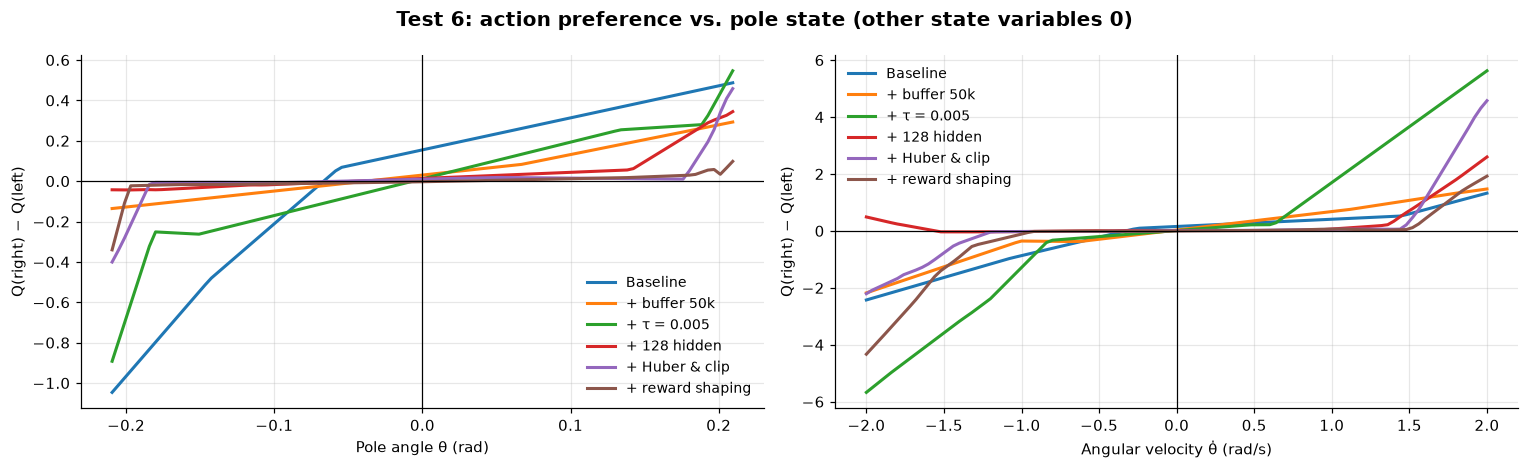

In [22]:
def preference(net: nn.Module, index: int, values: np.ndarray) -> np.ndarray:
    states = np.zeros((len(values), STATE_DIM), np.float32)
    states[:, index] = values
    q = q_values(net, states)
    return q[:, 1] - q[:, 0]


sweeps = [
    (2, np.linspace(-THETA_LIMIT, THETA_LIMIT, 101), "Pole angle θ (rad)"),
    (3, np.linspace(-2, 2, 101), "Angular velocity θ̇ (rad/s)"),
]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for ax, (index, values, xlabel) in zip(axes, sweeps):
    for i, c in enumerate(LADDER):
        ax.plot(
            values,
            preference(RUNS[c.name].model, index, values),
            color=COLORS[i],
            lw=2,
            label=c.label,
        )
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(0, color="black", lw=0.8)
    ax.set(xlabel=xlabel, ylabel="Q(right) − Q(left)")
    ax.legend(fontsize=9)

    pref = preference(BEST.model, index, values)
    largest_drop = -np.diff(pref).min()
    check(
        f"T6 reported network pushes towards the falling side ({xlabel.split(' (')[0]})",
        pref[0] < 0 < pref[-1] and largest_drop < 0.01,
        f"ends {pref[0]:+.2f} / {pref[-1]:+.2f}, largest decrease {max(largest_drop, 0):.4f}, "
        f"linear r = {np.corrcoef(values, pref)[0, 1]:.3f}, bias at 0 = {preference(BEST.model, index, np.zeros(1))[0]:+.3f}",
    )
fig.suptitle(
    "Test 6: action preference vs. pole state (other state variables 0)",
    fontsize=13,
    fontweight="bold",
)
fig.tight_layout()
save_figure(fig, "test_policy_response")
plt.show()

**Result.**
- **Angular velocity $\dot\theta$: passes.** The preference is monotone and correctly signed, from −4.33 to +1.92.
- **Pole angle $\theta$: fails.** The sign is correct at both ends (−0.34 / +0.10). For $|\theta| < 0.18$, however, the curve is flat at ≈ 0, and close to $\theta = 0.2$ it decreases by 0.024 (the threshold is 0.01).
- **Why.**
  - With $\dot\theta = 0$, every angle below ≈ 0.18 is recoverable with either action, so both Q-values are ≈ 20. The v5 network decides mostly by the angular velocity, whose preference range is about 10× larger.
  - The small dip lies in the edge region that the trained agent rarely visits. This is the same effect as T1a.
- **Earlier variants.** The baseline and v1 have more "textbook-like", nearly linear curves but balance much worse. A clean response curve is therefore not needed for good control.

### Test 7: Harder evaluation

**What:** The standard greedy evaluation can saturate at 500. Every evaluated network is additionally tested with 5 % random actions ($\epsilon = 0.05$) and from wider start states (±0.2, close to the failure angle 0.21). **Criterion:** the reported network solves the standard evaluation (mean ≥ 475).

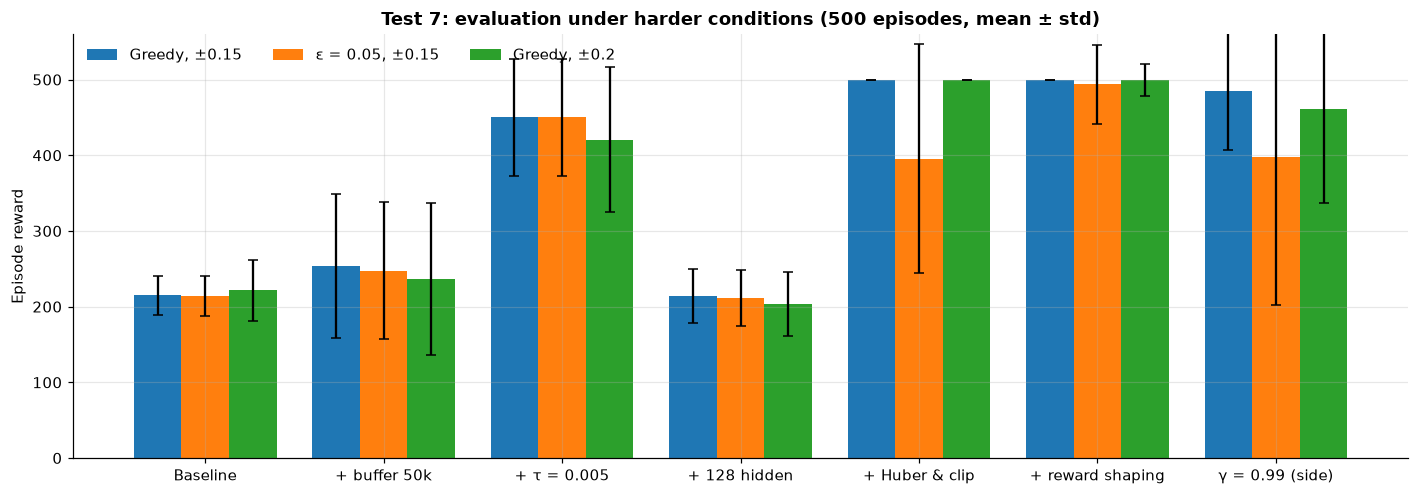

Variant           Greedy, ±0.15  ε = 0.05, ±0.15  Greedy, ±0.2 
----------------  -------------  ---------------  -------------
Baseline          215.1 ± 26.0   214.1 ± 26.4     221.5 ± 40.4 
+ buffer 50k      253.5 ± 95.2   247.7 ± 90.7     236.3 ± 100.5
+ τ = 0.005       450.2 ± 77.3   450.1 ± 77.7     420.8 ± 96.3 
+ 128 hidden      213.4 ± 35.7   211.8 ± 36.7     203.5 ± 42.1 
+ Huber & clip    500.0 ± 0.0    395.5 ± 151.6    500.0 ± 0.0  
+ reward shaping  500.0 ± 0.0    494.0 ± 52.3     499.1 ± 21.0 
γ = 0.99 (side)   485.3 ± 78.8   397.4 ± 194.8    460.6 ± 123.3
[PASS] T7 reported network solves the standard evaluation: mean = 500.0


In [23]:
conditions = {
    "Greedy, ±0.15": dict(),
    "ε = 0.05, ±0.15": dict(eps=0.05),
    "Greedy, ±0.2": dict(start=WIDE_START),
}
hard = {
    name: {
        cond: (EVALS[name] if not kw else evaluate(r.model, **kw))["lengths"]
        for cond, kw in conditions.items()
    }
    for name, r in RUNS.items()
}

fig, ax = plt.subplots(figsize=(13, 4.6))
width = 0.8 / len(conditions)
names = list(RUNS)
for j, cond in enumerate(conditions):
    means = [hard[n][cond].mean() for n in names]
    stds = [hard[n][cond].std() for n in names]
    ax.bar(
        np.arange(len(names)) + (j - 1) * width,
        means,
        width,
        yerr=stds,
        capsize=3,
        color=COLORS[j],
        label=cond,
    )
ax.set_xticks(np.arange(len(names)), [RUNS[n].config.label for n in names])
ax.set(
    title="Test 7: evaluation under harder conditions (500 episodes, mean ± std)",
    ylabel="Episode reward",
    ylim=(0, 560),
)
ax.legend(loc="upper left", ncols=3)
fig.tight_layout()
save_figure(fig, "test_harder_evaluation")
plt.show()

print_table(
    [
        {"Variant": RUNS[n].config.label}
        | {c: f"{hard[n][c].mean():.1f} ± {hard[n][c].std():.1f}" for c in conditions}
        for n in names
    ]
)
check(
    "T7 reported network solves the standard evaluation",
    EVALS[BEST.config.name]["lengths"].mean() >= SOLVED,
    f"mean = {EVALS[BEST.config.name]['lengths'].mean():.1f}",
)

**Result.** T7 passes: the reported network averages 500.0 on the standard evaluation.
- **v5 is also the most robust variant:**
  - with 5 % random actions it scores 494.0 ± 52.3, compared with 395.5 ± 151.6 for v4;
  - from start states of ±0.2 it scores 499.1 ± 21.0.
- **v4 is perfect greedily but brittle under noise.** Random pushes move the cart, and without shaping v4 does not bring it back to the centre. The $\gamma = 0.99$ run (397.4 with noise) is also less robust than v5.
- **The weak variants barely change under noise** (v0: 215.1 → 214.1), because they fail by cart drift anyway.

### Test 8: Why do episodes end?

**What:** An episode ends when the pole falls, the cart leaves the track, or at the time limit. Counted per block of 100 training episodes, plus the median of the largest $|x|$ in the greedy evaluation.

**Criteria:** both fixes of the short horizon reduce the cart failures during training compared with their parent v4: (a) the longer horizon ($\gamma = 0.99$, otherwise identical to v4), (b) reward shaping (v5).

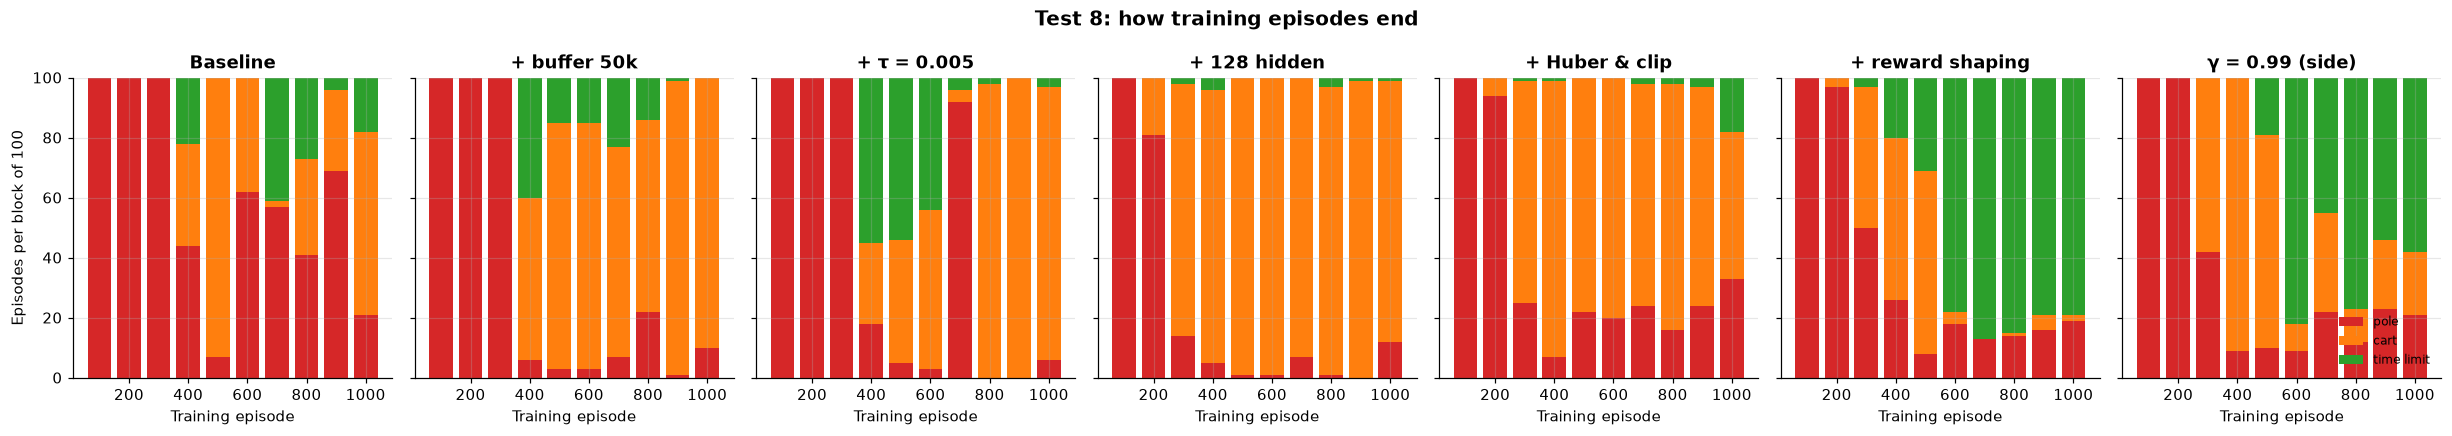

Variant           Training: pole / cart / limit  Evaluation: pole / cart / limit  Median max |x| (eval)
----------------  -----------------------------  -------------------------------  ---------------------
Baseline          601 / 287 / 112                0 / 500 / 0                      2.41                 
+ buffer 50k      352 / 540 / 108                0 / 478 / 22                     2.41                 
+ τ = 0.005       424 / 414 / 162                0 / 177 / 323                    1.18                 
+ 128 hidden      222 / 767 / 11                 0 / 500 / 0                      2.41                 
+ Huber & clip    365 / 608 / 27                 0 / 0 / 500                      0.39                 
+ reward shaping  361 / 177 / 462                0 / 0 / 500                      0.15                 
γ = 0.99 (side)   348 / 317 / 335                17 / 0 / 483                     1.74                 
[PASS] T8a longer horizon (γ = 0.99) reduces cart failures vs. v

In [24]:
fig, axes = plt.subplots(1, len(RUNS), figsize=(3.2 * len(RUNS), 4), sharey=True)
end_colors = [COLORS[3], COLORS[1], COLORS[2]]
for ax, (name, r) in zip(axes, RUNS.items()):
    blocks = r.log["end"].reshape(-1, 100)
    counts = np.array([(blocks == i).sum(axis=1) for i in range(len(END_NAMES))])
    bottom = np.zeros(blocks.shape[0])
    x = np.arange(1, blocks.shape[0] + 1) * 100
    for i, end in enumerate(END_NAMES):
        ax.bar(x, counts[i], width=80, bottom=bottom, color=end_colors[i], label=end)
        bottom += counts[i]
    ax.set(title=r.config.label, xlabel="Training episode")
axes[0].set_ylabel("Episodes per block of 100")
axes[-1].legend(loc="lower right", fontsize=8)
fig.suptitle("Test 8: how training episodes end", fontsize=13, fontweight="bold")
fig.tight_layout()
save_figure(fig, "test_end_reasons")
plt.show()

rows = []
for name, r in RUNS.items():
    train_counts = [(r.log["end"] == i).sum() for i in range(len(END_NAMES))]
    eval_counts = [(EVALS[name]["ends"] == i).sum() for i in range(len(END_NAMES))]
    rows.append(
        {
            "Variant": r.config.label,
            "Training: pole / cart / limit": " / ".join(map(str, train_counts)),
            "Evaluation: pole / cart / limit": " / ".join(map(str, eval_counts)),
            "Median max |x| (eval)": f"{np.median(EVALS[name]['max_abs_x']):.2f}",
        }
    )
print_table(rows)


def cart_failures(name: str) -> int:
    return int((RUNS[name].log["end"] == END_NAMES.index("cart")).sum())


check(
    "T8a longer horizon (γ = 0.99) reduces cart failures vs. v4",
    cart_failures(SIDE_GAMMA.name) < cart_failures("v4_huber"),
    f"v4: {cart_failures('v4_huber')}, γ = 0.99: {cart_failures(SIDE_GAMMA.name)}",
)
check(
    "T8b reward shaping (v5) reduces cart failures vs. v4",
    cart_failures("v5_shaping") < cart_failures("v4_huber"),
    f"v4: {cart_failures('v4_huber')}, v5: {cart_failures('v5_shaping')}",
)

**Result.** Both checks pass.
- **Cart failures in training, compared with v4 (608 of 1,000 episodes):**
  - $\gamma = 0.99$ cuts them to 317 (T8a);
  - reward shaping cuts them to 177 (T8b). v5 also has the most episodes reaching the time limit (462).
- **Evaluation.**
  - The baseline and "+ 128 hidden" lose **every** evaluation episode by the cart leaving the track, while the pole stays up. Their median max $|x|$ is 2.41, i.e. at the edge.
  - Pole failures almost never occur in evaluation; the exception is $\gamma = 0.99$, with 17.
- **Takeaway: with $\gamma = 0.95$, balancing the pole is easy, and keeping the cart on the track is the actual difficulty.**

### Test 9: Reproducibility

**What:** The same short training (30 episodes, learning after 64 transitions) twice with the same seed must give identical rewards and identical weights; a different seed must give different rewards.

In [25]:
REPRO = replace(BASELINE, name="test_repro", episodes=30, learning_starts=64)
log_a, snap_a = train(REPRO, seed=123, progress=False)
log_b, snap_b = train(REPRO, seed=123, progress=False)
log_c, _ = train(REPRO, seed=124, progress=False)
same_weights = all(torch.equal(snap_a[30][k], snap_b[30][k]) for k in snap_a[30])
check(
    "T9a same seed: identical rewards and weights",
    np.array_equal(log_a["reward"], log_b["reward"]) and same_weights,
)
check(
    "T9b different seed: different rewards",
    not np.array_equal(log_a["reward"], log_c["reward"]),
)

[PASS] T9a same seed: identical rewards and weights
[PASS] T9b different seed: different rewards


**Result.** Passed. The same seed gives identical rewards and weights, and a different seed gives different rewards. All results above are therefore reproducible from the cached configs and seeds.

### Summary of all checks

In [26]:
n_pass = sum(passed for _, passed in CHECKS)
print(f"{n_pass}/{len(CHECKS)} checks passed")
for name, passed in CHECKS:
    print(f"  [{'PASS' if passed else 'FAIL'}] {name}")

17/21 checks passed
  [FAIL] T1a Baseline: Q right before a failure is small
  [PASS] T1b Baseline: Q correlates with the actual return
  [PASS] T1d Baseline: no runaway overestimation
  [FAIL] T1a + reward shaping: Q right before a failure is small
  [FAIL] T1b + reward shaping: Q correlates with the actual return
  [PASS] T1c + reward shaping: truncation is bootstrapped (Q stays high)
  [PASS] T1d + reward shaping: no runaway overestimation
  [PASS] T2 γ = 0: Q = 1 for every state and action
  [PASS] T3a normal training learns
  [PASS] T3b learning rate 0: weights unchanged, no learning
  [PASS] T3c negated reward: learns to fail fast
  [PASS] T4a without a target network Q diverges
  [PASS] T4b Double DQN overestimates less than vanilla DQN
  [PASS] T5 converged: small TD error along a greedy episode
  [FAIL] T6 reported network pushes towards the falling side (Pole angle θ)
  [PASS] T6 reported network pushes towards the falling side (Angular velocity θ̇)
  [PASS] T7 reported netwo

**Result: 17 of 21 checks pass.** The four failures share one cause:
- **The failures.** T1a for the baseline and for v5, T1b for v5, and T6 for the pole angle $\theta$.
- **The cause: the Q-function is only accurate where the replay buffer has data.**
  - A good agent rarely visits near-failure states, so Q there is extrapolated from the plateau at 20 (T1a, T6).
  - With $\gamma = 0.95$, Q saturates at 20 in all safe states, so the action gaps are tiny (≈ 0.002, Test 5).
- **T1b is in addition limited by the test design.** It compares Q of greedy behaviour with returns of a noisy policy.
- **What would fix it.** These failures are not bugs in the update rule: T2, T3, T4a and T5 confirm the targets, the terminal mask and the target network. Ideas for "three more months":
  - prioritized replay, or keeping failure transitions in the buffer longer;
  - training from wider or perturbed start states;
  - for T1, a calibration test with greedy continuation.